In [53]:
from google.colab import files
uploaded = files.upload()

In [55]:
import zipfile
filename = next(iter(uploaded))

print("Valid ZIP:", zipfile.is_zipfile(filename))

with zipfile.ZipFile(filename) as z:
    names = z.namelist()

for name in names[:40]:
    print(name)

StopIteration: 

In [56]:
import zipfile

with zipfile.ZipFile(filename) as z:
    readme = z.read("README.txt").decode("utf-8", errors="replace")
    print("===== README =====")
    print(readme[:12000])

    path = "figures/figure10/followingBehavior-200bar-cycle4.txt"
    data = z.read(path).decode("utf-8", errors="replace")

    print("\n===== EXPERIMENT DATA =====")
    print("\n".join(data.splitlines()[:20]))

===== README =====

% ----------------------------------------------------------------
Injection Molding Process Data for Post-Consumer-Recycled Materials
% ----------------------------------------------------------------

Data set for: Part-mass control in injection molding of recycled thermoplastics by learning-enabled model predictive cavity-pressure control

%% INFORMATION:

Abstract: 
The data set shown here contains recorded experimental data for the injection molding of a Post-Consumer-Recycled (PCR) material (Systalen PP-24000 gr000, supplied by Systec GmbH) and virgin material (PP579S, supplied by Sabic Deutschland GmbH) using a flat-plate geometry. The data set includes experiments controlled by a learning-based nonlinear model predictive controller and proportional controller for cavity-pressure control. Each measurement record includes the pressures in the screw antechamber and inside the cavity, the controller output, as well as the screw velocity, and the volume of the sc

In [57]:
import pandas as pd
import matplotlib.pyplot as plt
import zipfile
from io import StringIO

path = "figures/figure10/followingBehavior-200bar-cycle4.txt"

with zipfile.ZipFile(filename) as z:
    content = z.read(path).decode("utf-8")

df = pd.read_csv(StringIO(content), sep=r"\s+")

print(df.shape)
print(df.head())
print(df.describe().round(2))


(625, 6)
    time       p_C       p_S       v_S        V_S  u_S
0  0.008 -2.487546 -1.690369 -0.042317  44.243638 -1.0
1  0.016 -2.138763 -1.601868 -0.072412  44.255728 -1.0
2  0.024 -2.553354 -1.416016 -0.080486  44.261486 -1.0
3  0.032 -2.619163 -1.601868 -0.095901  44.315605 -1.0
4  0.040 -2.829749 -1.053162 -0.049657  44.225790 -1.0
         time     p_C     p_S     v_S     V_S     u_S
count  625.00  625.00  625.00  625.00  625.00  625.00
mean     2.50  134.49  203.35    7.59   14.24   -0.39
std      1.44   85.12   56.31    9.43   11.75    0.45
min      0.01   -3.31   -1.69   -0.10    6.07   -1.00
25%      1.26   38.56  181.14    0.38    6.64   -1.00
50%      2.50  199.97  231.36    0.50    7.27   -0.04
75%      3.75  200.66  237.21   20.80   19.96   -0.03
max      5.00  202.10  243.71   20.93   44.32   -0.03


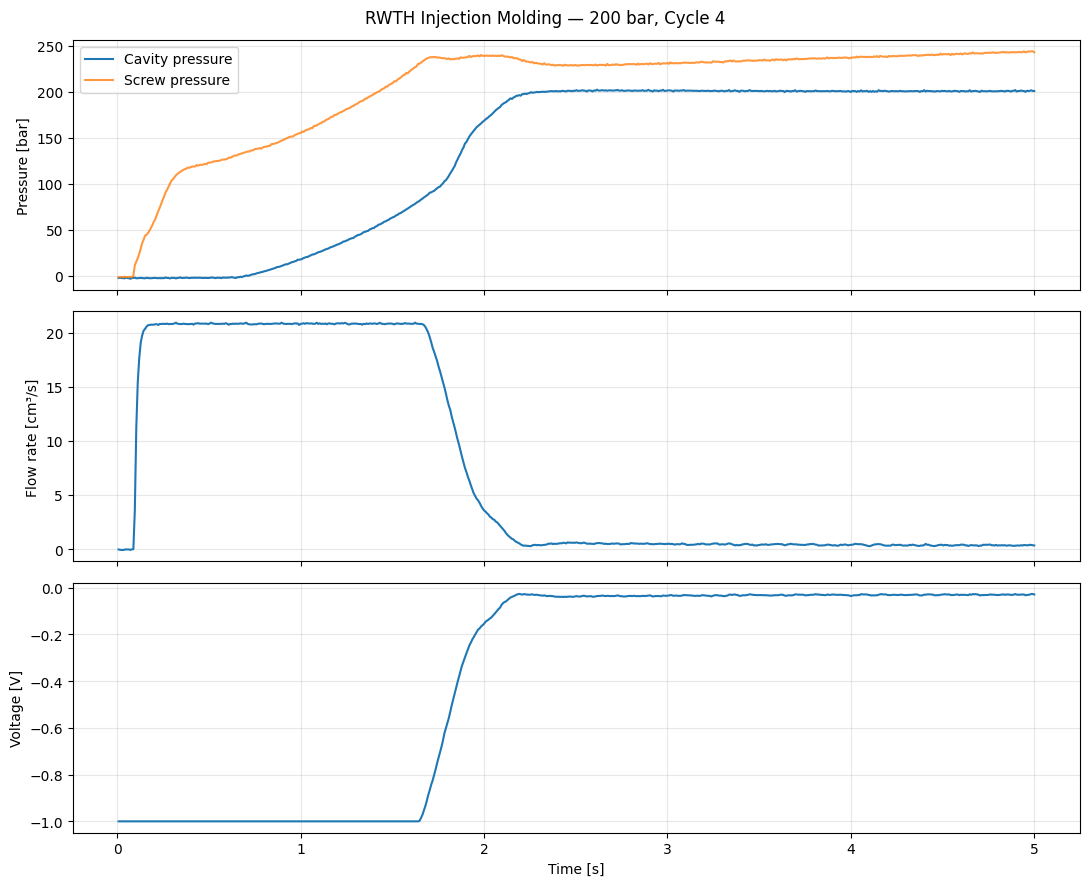

In [58]:
fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

ax[0].plot(df["time"], df["p_C"], label="Cavity pressure")
ax[0].plot(df["time"], df["p_S"], label="Screw pressure", alpha=0.8)
ax[0].set_ylabel("Pressure [bar]")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].plot(df["time"], df["v_S"])
ax[1].set_ylabel("Flow rate [cm³/s]")
ax[1].grid(alpha=0.3)

ax[2].plot(df["time"], df["u_S"], label="Control voltage")
ax[2].set_ylabel("Voltage [V]")
ax[2].set_xlabel("Time [s]")
ax[2].grid(alpha=0.3)

plt.suptitle("RWTH Injection Molding — 200 bar, Cycle 4")
plt.tight_layout()
plt.show()


Measured final volume: 6.126 cm³
Simulated final volume: 6.292 cm³
RMSE: 0.2005 cm³


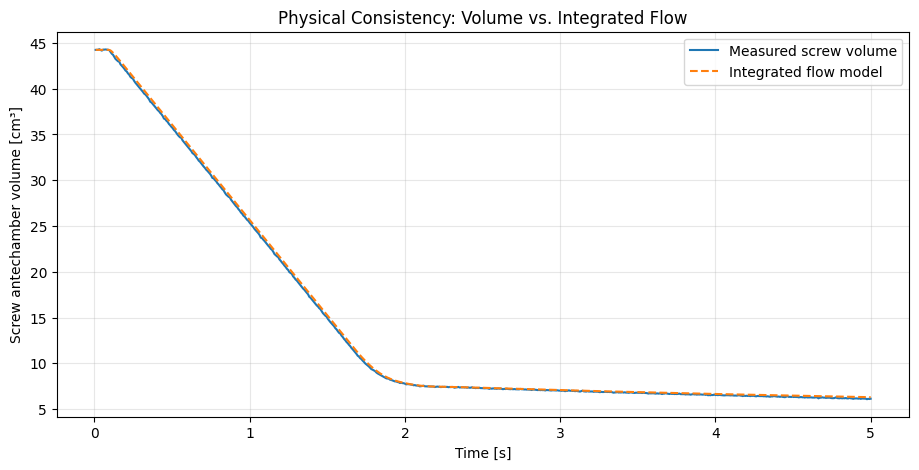

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid

t = df["time"].to_numpy()
flow = df["v_S"].to_numpy()
volume = df["V_S"].to_numpy()

volume_model = volume[0] - cumulative_trapezoid(
    flow, t, initial=0
)

rmse = np.sqrt(np.mean((volume - volume_model)**2))

print(f"Measured final volume: {volume[-1]:.3f} cm³")
print(f"Simulated final volume: {volume_model[-1]:.3f} cm³")
print(f"RMSE: {rmse:.4f} cm³")

plt.figure(figsize=(11, 5))

plt.plot(t, volume, label="Measured screw volume")
plt.plot(t, volume_model, "--", label="Integrated flow model")

plt.xlabel("Time [s]")
plt.ylabel("Screw antechamber volume [cm³]")
plt.title("Physical Consistency: Volume vs. Integrated Flow")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


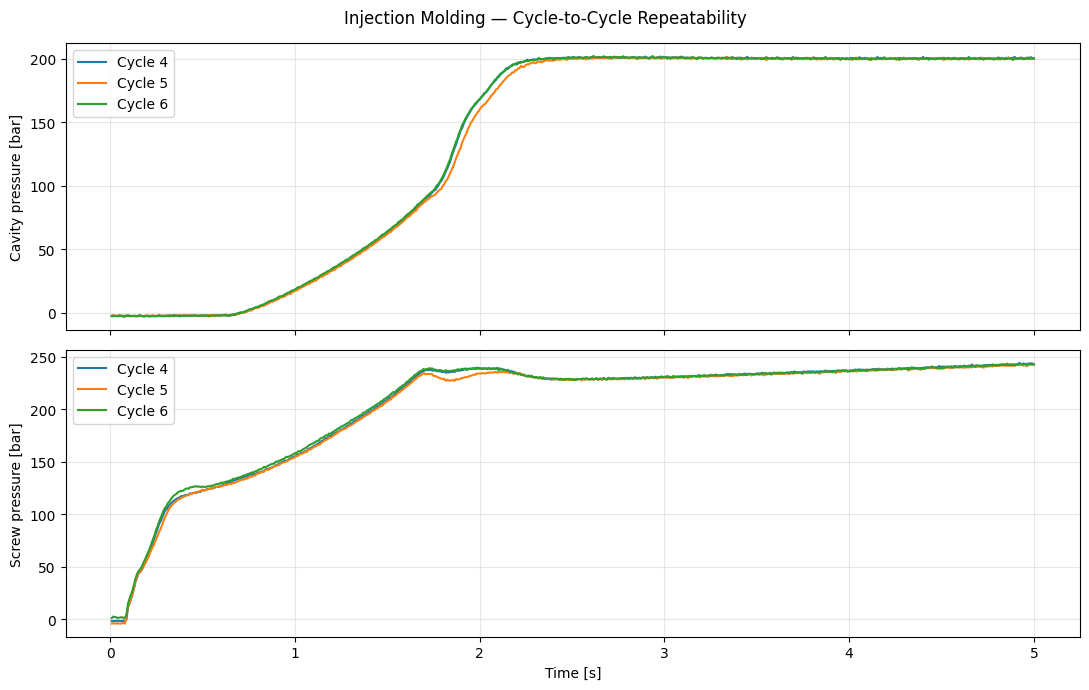

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO
import zipfile

cycles = {}

with zipfile.ZipFile(filename) as z:
    for n in [4, 5, 6]:
        path = f"figures/figure10/followingBehavior-200bar-cycle{n}.txt"
        text = z.read(path).decode("utf-8")
        cycles[n] = pd.read_csv(StringIO(text), sep=r"\s+")

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

for n, data in cycles.items():
    ax[0].plot(data["time"], data["p_C"], label=f"Cycle {n}")
    ax[1].plot(data["time"], data["p_S"], label=f"Cycle {n}")

ax[0].set_ylabel("Cavity pressure [bar]")
ax[1].set_ylabel("Screw pressure [bar]")
ax[1].set_xlabel("Time [s]")

for a in ax:
    a.legend()
    a.grid(alpha=0.3)

plt.suptitle("Injection Molding — Cycle-to-Cycle Repeatability")
plt.tight_layout()
plt.show()


In [61]:
import numpy as np
from scipy.integrate import cumulative_trapezoid
from scipy.optimize import least_squares

def simulate_pressure(data, params):
    F50, w, dp, tau = params

    t = data["time"].to_numpy()
    pS = data["p_S"].to_numpy()
    flow = data["v_S"].to_numpy()

    F = cumulative_trapezoid(flow, t, initial=0)

    g = 1 / (1 + np.exp(-np.clip((F - F50) / w, -60, 60)))
    p_eq = g * np.maximum(pS - dp, 0)

    p_hat = np.zeros(len(t))
    p_hat[0] = data["p_C"].iloc[0]

    for k in range(len(t) - 1):
        dt = t[k + 1] - t[k]
        alpha = np.exp(-dt / tau)
        p_hat[k + 1] = alpha * p_hat[k] + (1 - alpha) * p_eq[k]

    return p_hat


In [62]:
train = cycles[4]

def residuals(params):
    prediction = simulate_pressure(train, params)
    return prediction - train["p_C"].to_numpy()

result = least_squares(
    residuals,
    x0=[28, 6, 30, 0.15],
    bounds=(
        [0, 0.1, 0, 0.005],
        [45, 25, 150, 3]
    )
)

params = result.x

for name, value in zip(["F50", "w", "dp", "tau"], params):
    print(f"{name:5s} = {value:.4f}")

print("Optimization succeeded:", result.success)


F50   = 27.7147
w     = 5.2827
dp    = 0.0000
tau   = 0.2787
Optimization succeeded: True


Cycle 4: RMSE = 7.675 bar, MAE = 6.095 bar
Cycle 5: RMSE = 8.043 bar, MAE = 6.116 bar
Cycle 6: RMSE = 7.696 bar, MAE = 6.093 bar


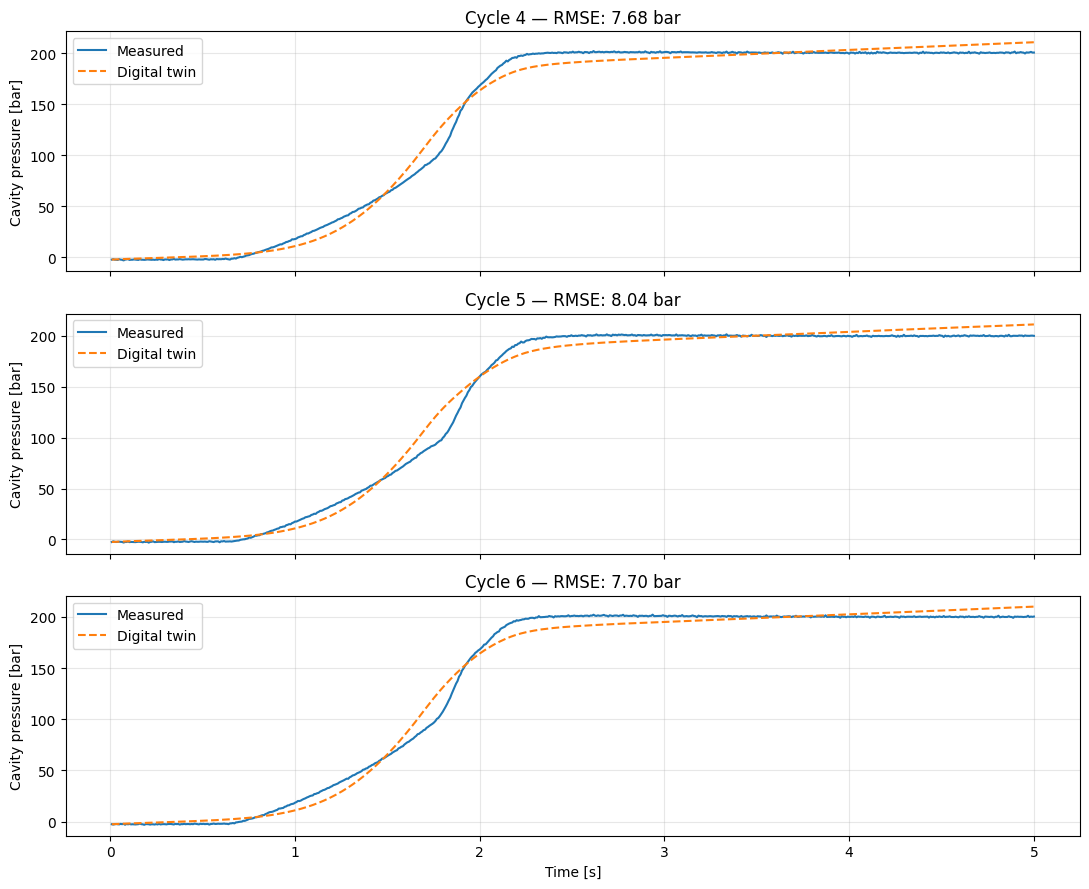

In [63]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

for a, n in zip(ax, [4, 5, 6]):
    data = cycles[n]

    measured = data["p_C"].to_numpy()
    predicted = simulate_pressure(data, params)

    rmse = np.sqrt(np.mean((measured - predicted)**2))
    mae = np.mean(np.abs(measured - predicted))

    print(f"Cycle {n}: RMSE = {rmse:.3f} bar, MAE = {mae:.3f} bar")

    a.plot(data["time"], measured, label="Measured")
    a.plot(data["time"], predicted, "--", label="Digital twin")

    a.set_title(f"Cycle {n} — RMSE: {rmse:.2f} bar")
    a.set_ylabel("Cavity pressure [bar]")
    a.grid(alpha=0.3)
    a.legend()

ax[-1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()


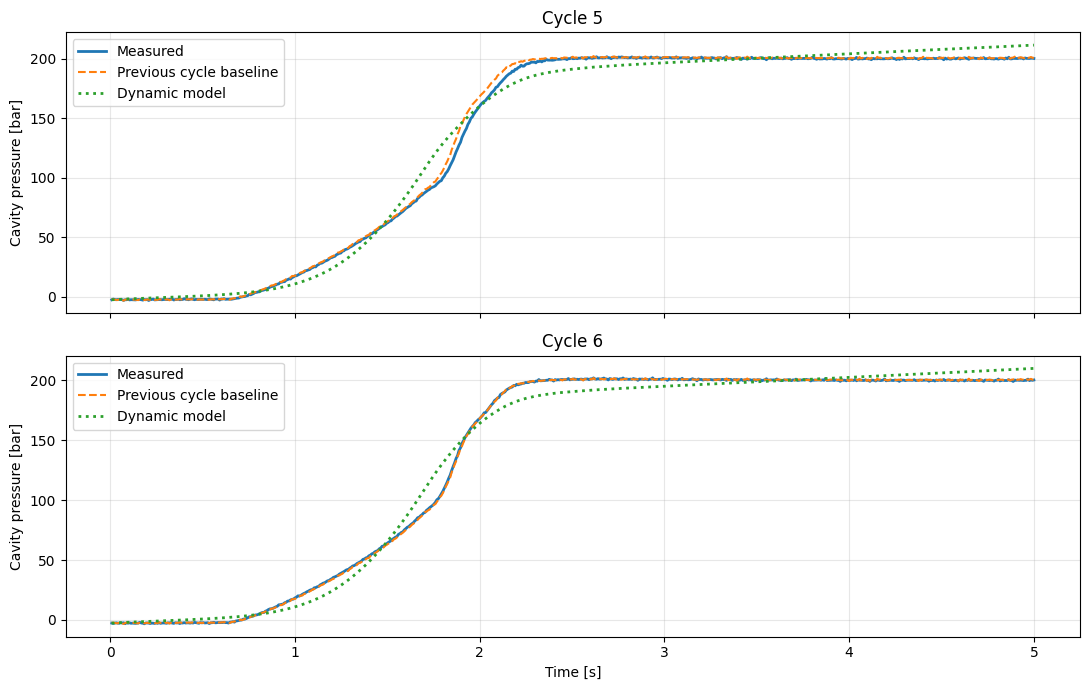

   Cycle  Baseline RMSE  Digital Twin RMSE
0      5          2.775              8.043
1      6          0.659              7.696


In [64]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

reference = cycles[4]
results = []

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

for a, n in zip(ax, [5, 6]):
    data = cycles[n]

    t = data["time"].to_numpy()
    measured = data["p_C"].to_numpy()

    baseline = np.interp(
        t,
        reference["time"],
        reference["p_C"]
    )

    twin = simulate_pressure(data, params)

    rmse_baseline = np.sqrt(np.mean((measured - baseline)**2))
    rmse_twin = np.sqrt(np.mean((measured - twin)**2))

    results.append([n, rmse_baseline, rmse_twin])

    a.plot(t, measured, label="Measured", linewidth=2)
    a.plot(t, baseline, "--", label="Previous cycle baseline")
    a.plot(t, twin, ":", label="Dynamic model", linewidth=2)

    a.set_title(f"Cycle {n}")
    a.set_ylabel("Cavity pressure [bar]")
    a.legend()
    a.grid(alpha=0.3)

ax[-1].set_xlabel("Time [s]")

plt.tight_layout()
plt.show()

comparison = pd.DataFrame(
    results,
    columns=["Cycle", "Baseline RMSE", "Digital Twin RMSE"]
)

print(comparison.round(3))


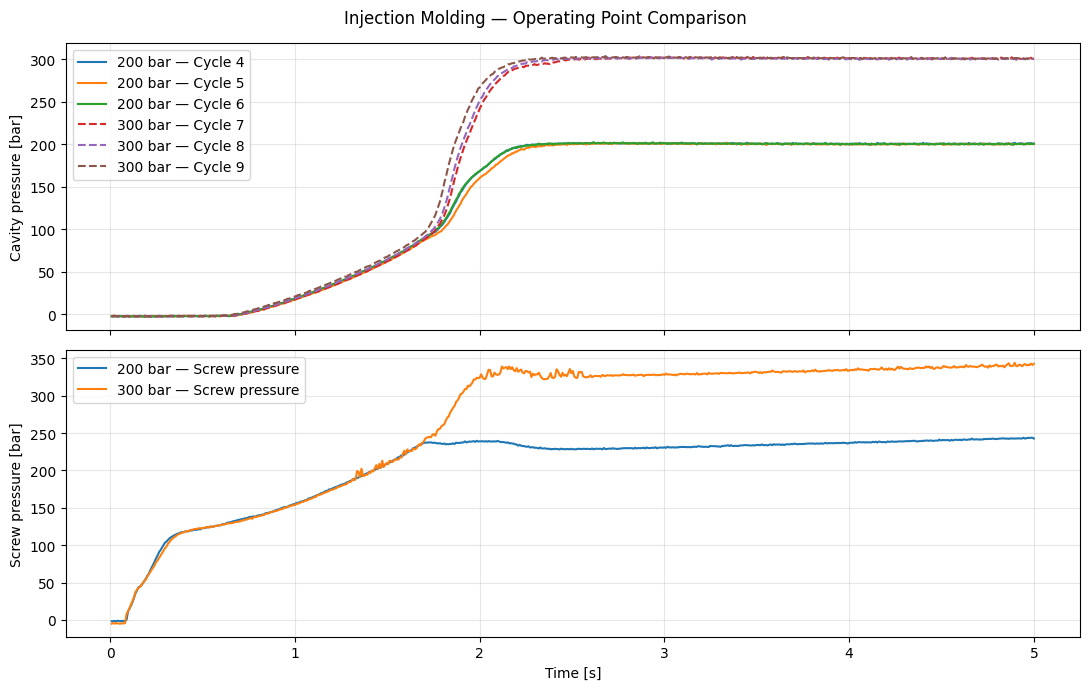

In [65]:
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO
import zipfile

cycles_300 = {}

with zipfile.ZipFile(filename) as z:
    for n in [7, 8, 9]:
        path = f"figures/figure10/followingBehavior-300bar-cycle{n}.txt"
        content = z.read(path).decode("utf-8")
        cycles_300[n] = pd.read_csv(StringIO(content), sep=r"\s+")

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

for n in [4, 5, 6]:
    data = cycles[n]
    ax[0].plot(data["time"], data["p_C"], label=f"200 bar — Cycle {n}")

for n in [7, 8, 9]:
    data = cycles_300[n]
    ax[0].plot(data["time"], data["p_C"], "--", label=f"300 bar — Cycle {n}")

ax[0].set_ylabel("Cavity pressure [bar]")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].plot(cycles[4]["time"], cycles[4]["p_S"],
           label="200 bar — Screw pressure")
ax[1].plot(cycles_300[7]["time"], cycles_300[7]["p_S"],
           label="300 bar — Screw pressure")

ax[1].set_ylabel("Screw pressure [bar]")
ax[1].set_xlabel("Time [s]")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.suptitle("Injection Molding — Operating Point Comparison")
plt.tight_layout()
plt.show()


300 bar — Cycle 7: RMSE = 15.019 bar
300 bar — Cycle 8: RMSE = 17.083 bar
300 bar — Cycle 9: RMSE = 20.469 bar


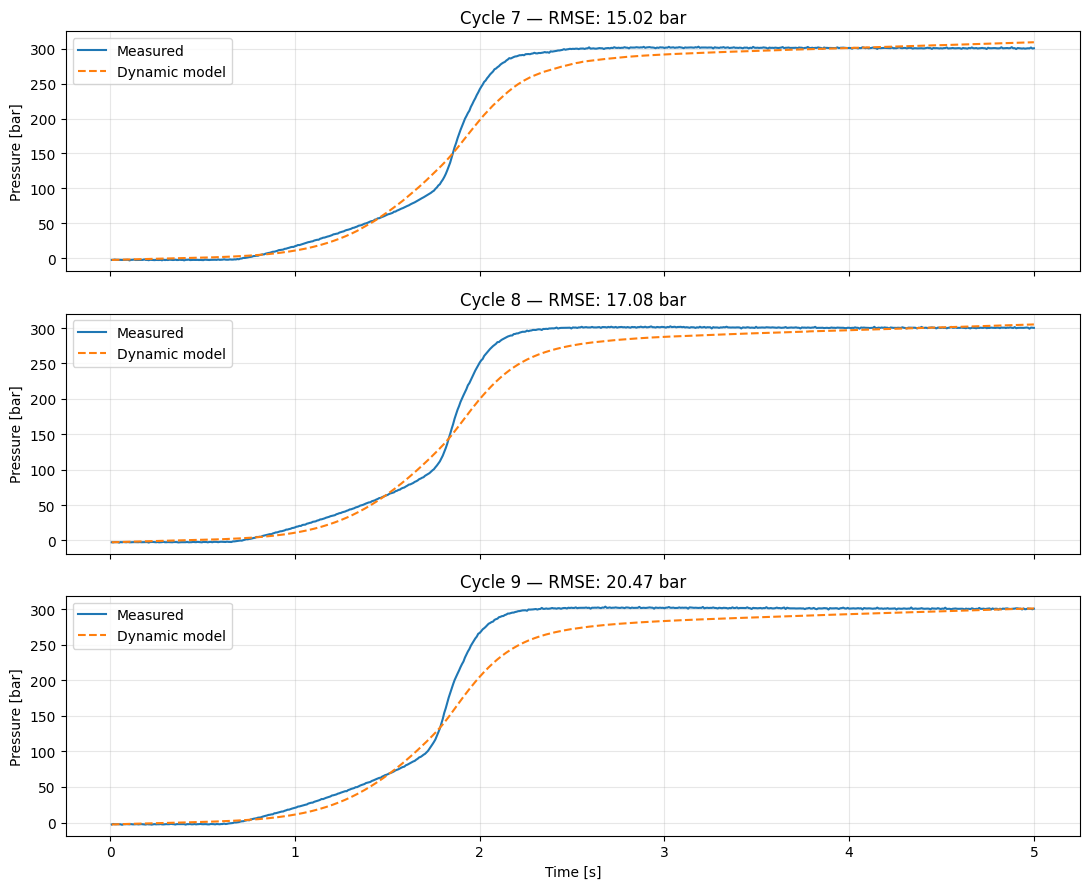

In [66]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

for a, n in zip(ax, [7, 8, 9]):
    data = cycles_300[n]

    measured = data["p_C"].to_numpy()
    predicted = simulate_pressure(data, params)

    rmse = np.sqrt(np.mean((measured - predicted)**2))

    print(f"300 bar — Cycle {n}: RMSE = {rmse:.3f} bar")

    a.plot(data["time"], measured, label="Measured")
    a.plot(data["time"], predicted, "--", label="Dynamic model")

    a.set_ylabel("Pressure [bar]")
    a.set_title(f"Cycle {n} — RMSE: {rmse:.2f} bar")
    a.legend()
    a.grid(alpha=0.3)

ax[-1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()


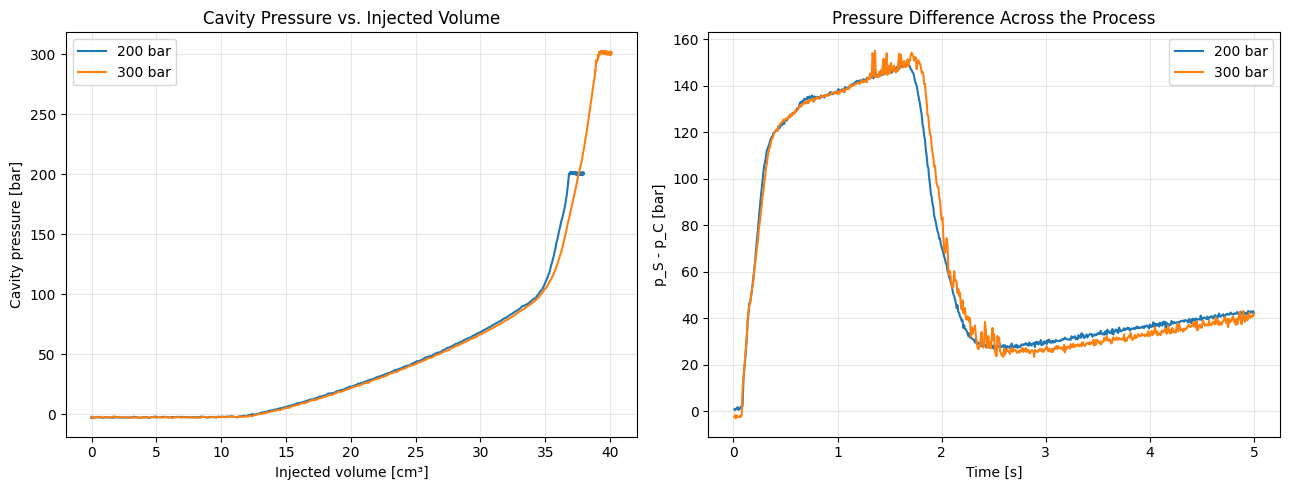

In [67]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

for n, data, label in [
    (4, cycles[4], "200 bar"),
    (7, cycles_300[7], "300 bar")
]:
    t = data["time"].to_numpy()
    flow = data["v_S"].to_numpy()

    F = cumulative_trapezoid(flow, t, initial=0)

    pC = data["p_C"].to_numpy()
    pS = data["p_S"].to_numpy()

    ax[0].plot(F, pC, label=label)
    ax[1].plot(t, pS - pC, label=label)

ax[0].set_xlabel("Injected volume [cm³]")
ax[0].set_ylabel("Cavity pressure [bar]")
ax[0].set_title("Cavity Pressure vs. Injected Volume")

ax[1].set_xlabel("Time [s]")
ax[1].set_ylabel("p_S - p_C [bar]")
ax[1].set_title("Pressure Difference Across the Process")

for a in ax:
    a.grid(alpha=0.3)
    a.legend()

plt.tight_layout()
plt.show()


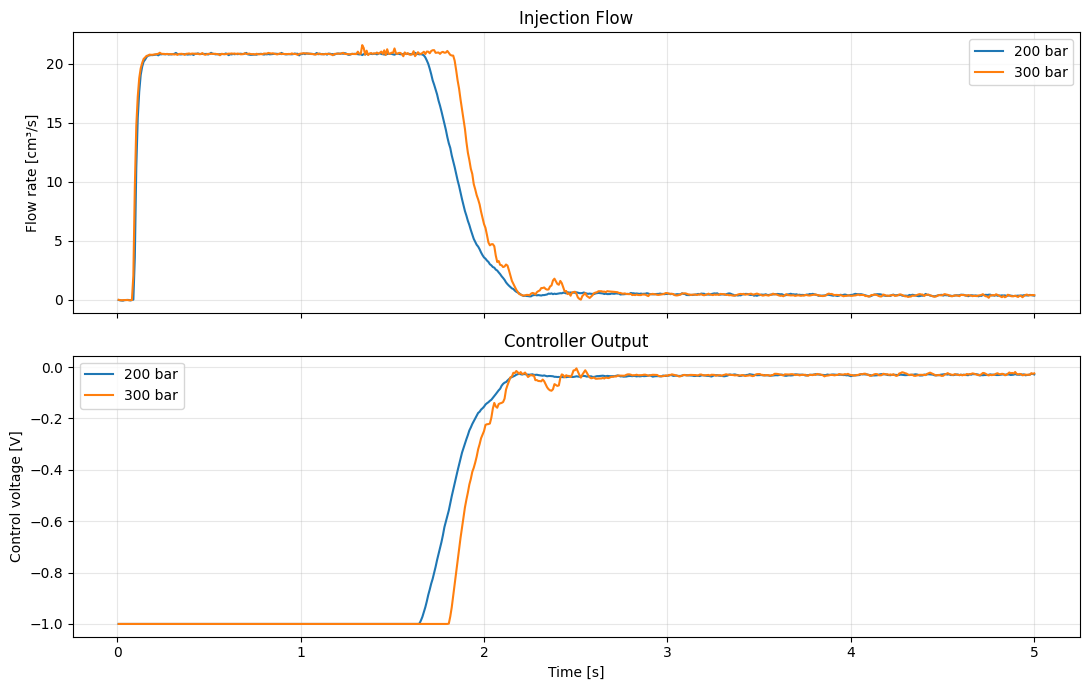

In [68]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

for data, label in [
    (cycles[4], "200 bar"),
    (cycles_300[7], "300 bar")
]:
    ax[0].plot(data["time"], data["v_S"], label=label)
    ax[1].plot(data["time"], data["u_S"], label=label)

ax[0].set_ylabel("Flow rate [cm³/s]")
ax[0].set_title("Injection Flow")

ax[1].set_ylabel("Control voltage [V]")
ax[1].set_xlabel("Time [s]")
ax[1].set_title("Controller Output")

for a in ax:
    a.grid(alpha=0.3)
    a.legend()

plt.tight_layout()
plt.show()


In [69]:
import numpy as np
import pandas as pd
from scipy.integrate import cumulative_trapezoid

rows = []

for n, data in {**cycles, **cycles_300}.items():
    t = data["time"].to_numpy()
    u = data["u_S"].to_numpy()
    q = data["v_S"].to_numpy()
    p = data["p_C"].to_numpy()

    F = cumulative_trapezoid(q, t, initial=0)

    # Geçişleri başlangıç hareketinden ayırıyoruz.
    after = t > 1.0

    i_u = np.flatnonzero(after & (u > -0.9))[0]
    i_q = np.flatnonzero(after & (q < 0.9 * np.max(q)))[0]
    i_p = np.flatnonzero(after & (p >= 100))[0]

    rows.append([
        n, t[i_u], t[i_q], t[i_p],
        F[i_u], p[i_u]
    ])

events = pd.DataFrame(rows, columns=[
    "Cycle", "Control change [s]", "Flow drop [s]",
    "100 bar [s]", "Volume at switch [cm³]",
    "Pressure at switch [bar]"
])

print(events.round(3).to_string(index=False))


 Cycle  Control change [s]  Flow drop [s]  100 bar [s]  Volume at switch [cm³]  Pressure at switch [bar]
     4               1.696          1.720        1.776                  33.072                    88.380
     5               1.688          1.712        1.808                  32.983                    85.432
     6               1.688          1.720        1.768                  32.935                    87.972
     7               1.832          1.856        1.768                  36.112                   131.485
     8               1.824          1.856        1.752                  35.745                   136.493
     9               1.800          1.824        1.720                  35.333                   145.897


In [70]:

import numpy as np
from scipy.integrate import cumulative_trapezoid
from scipy.optimize import least_squares

def filling_data(data):
    t = data["time"].to_numpy()
    q = data["v_S"].to_numpy()
    u = data["u_S"].to_numpy()
    p = data["p_C"].to_numpy()

    F = cumulative_trapezoid(q, t, initial=0)

    switch = np.flatnonzero((t > 1.0) & (u > -0.9))[0]

    return F[:switch], p[:switch]

F_train, p_train = filling_data(cycles[4])

p0 = np.median(p_train[:10])

def filling_model(F, theta):
    a, F0, b = theta
    return p0 + a * np.maximum(F - F0, 0)**b

result_fill = least_squares(
    lambda theta: filling_model(F_train, theta) - p_train,
    x0=[0.5, 10, 1.5],
    bounds=([0, 0, 0.5], [10, 20, 4])
)

theta_fill = result_fill.x

print(f"Initial pressure p0 = {p0:.3f} bar")
print(f"a  = {theta_fill[0]:.4f}")
print(f"F0 = {theta_fill[1]:.4f} cm³")
print(f"b  = {theta_fill[2]:.4f}")


Initial pressure p0 = -2.553 bar
a  = 0.7363
F0 = 9.8834 cm³
b  = 1.5250


Cycle 4: Filling RMSE = 0.479 bar
Cycle 5: Filling RMSE = 1.067 bar
Cycle 6: Filling RMSE = 0.672 bar
Cycle 7: Filling RMSE = 2.746 bar
Cycle 8: Filling RMSE = 3.677 bar
Cycle 9: Filling RMSE = 5.910 bar


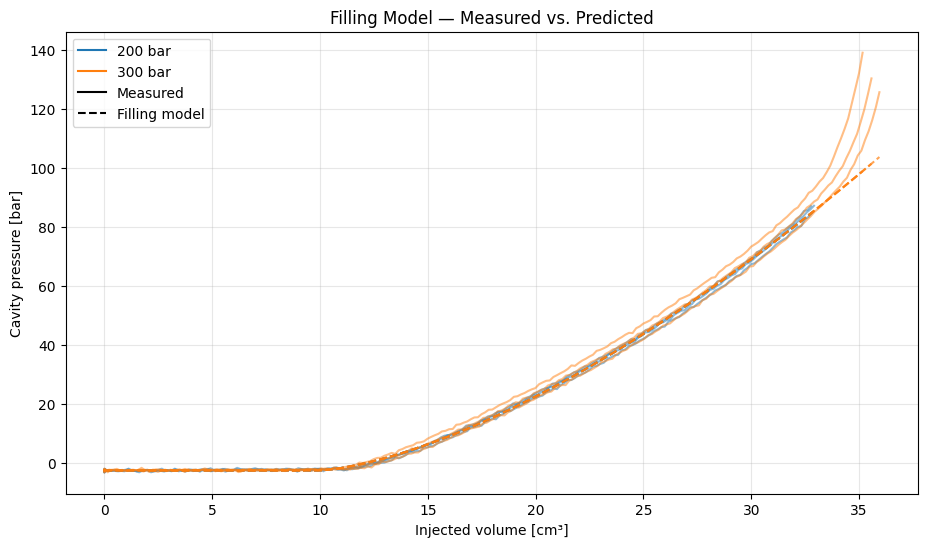

In [71]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 6))

all_cycles = {**cycles, **cycles_300}

for n, data in all_cycles.items():
    F, measured = filling_data(data)
    predicted = filling_model(F, theta_fill)

    rmse = np.sqrt(np.mean((measured - predicted)**2))

    print(f"Cycle {n}: Filling RMSE = {rmse:.3f} bar")

    color = "tab:blue" if n <= 6 else "tab:orange"

    ax.plot(F, measured, color=color, alpha=0.5)
    ax.plot(F, predicted, "--", color=color, alpha=0.7)

ax.set_xlabel("Injected volume [cm³]")
ax.set_ylabel("Cavity pressure [bar]")
ax.set_title("Filling Model — Measured vs. Predicted")

ax.plot([], [], color="tab:blue", label="200 bar")
ax.plot([], [], color="tab:orange", label="300 bar")
ax.plot([], [], color="black", linestyle="-", label="Measured")
ax.plot([], [], color="black", linestyle="--", label="Filling model")

ax.legend()
ax.grid(alpha=0.3)

plt.show()


In [72]:

from scipy.optimize import least_squares
from scipy.integrate import cumulative_trapezoid
import numpy as np

def hybrid_twin(data, p_ref, tau):
    t = data["time"].to_numpy()
    q = data["v_S"].to_numpy()
    u = data["u_S"].to_numpy()

    F = cumulative_trapezoid(q, t, initial=0)

    switch = np.flatnonzero((t > 1.0) & (u > -0.9))[0]

    p_hat = filling_model(F, theta_fill)

    t_switch = t[switch]
    p_switch = p_hat[switch]

    p_hat[switch:] = p_ref + (p_switch - p_ref) * np.exp(
        -(t[switch:] - t_switch) / tau
    )

    return p_hat


In [73]:

train = cycles[4]

def packing_residual(x):
    prediction = hybrid_twin(train, 200, x[0])

    t = train["time"].to_numpy()
    u = train["u_S"].to_numpy()
    switch = np.flatnonzero((t > 1.0) & (u > -0.9))[0]

    return prediction[switch:] - train["p_C"].to_numpy()[switch:]

fit = least_squares(
    packing_residual,
    x0=[0.2],
    bounds=([0.01], [2.0])
)

tau_p = fit.x[0]

print(f"Packing time constant: {tau_p:.4f} s")


Packing time constant: 0.2384 s


Cycle 4: Hybrid RMSE = 4.010 bar
Cycle 5: Hybrid RMSE = 5.592 bar
Cycle 6: Hybrid RMSE = 4.033 bar
Cycle 7: Hybrid RMSE = 11.069 bar
Cycle 8: Hybrid RMSE = 12.964 bar
Cycle 9: Hybrid RMSE = 15.506 bar


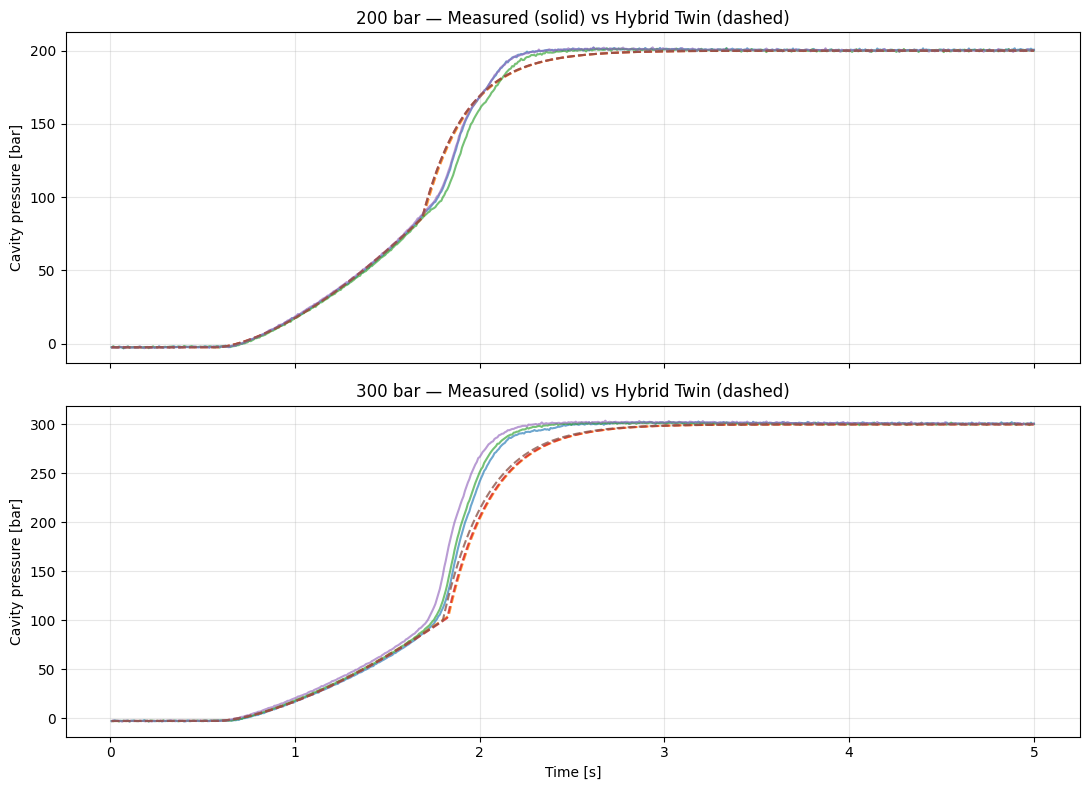

In [74]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

for n, data in {**cycles, **cycles_300}.items():

    p_ref = 200 if n <= 6 else 300

    measured = data["p_C"].to_numpy()
    predicted = hybrid_twin(data, p_ref, tau_p)

    rmse = np.sqrt(np.mean((measured - predicted)**2))

    print(f"Cycle {n}: Hybrid RMSE = {rmse:.3f} bar")

    a = ax[0] if n <= 6 else ax[1]

    a.plot(data["time"], measured, alpha=0.65)
    a.plot(data["time"], predicted, "--", alpha=0.8)

ax[0].set_title("200 bar — Measured (solid) vs Hybrid Twin (dashed)")
ax[1].set_title("300 bar — Measured (solid) vs Hybrid Twin (dashed)")

for a in ax:
    a.set_ylabel("Cavity pressure [bar]")
    a.grid(alpha=0.3)

ax[-1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()


 Cycle  Target [bar]  Measured t63 [s]  Twin t63 [s]  Measured t90 [s]  Twin t90 [s]
     4           200             0.256          0.24             0.432         0.552
     5           200             0.304          0.24             0.488         0.552
     6           200             0.264          0.24             0.432         0.552
     7           300             0.168          0.24             0.312         0.552
     8           300             0.152          0.24             0.304         0.552
     9           300             0.144          0.24             0.280         0.552


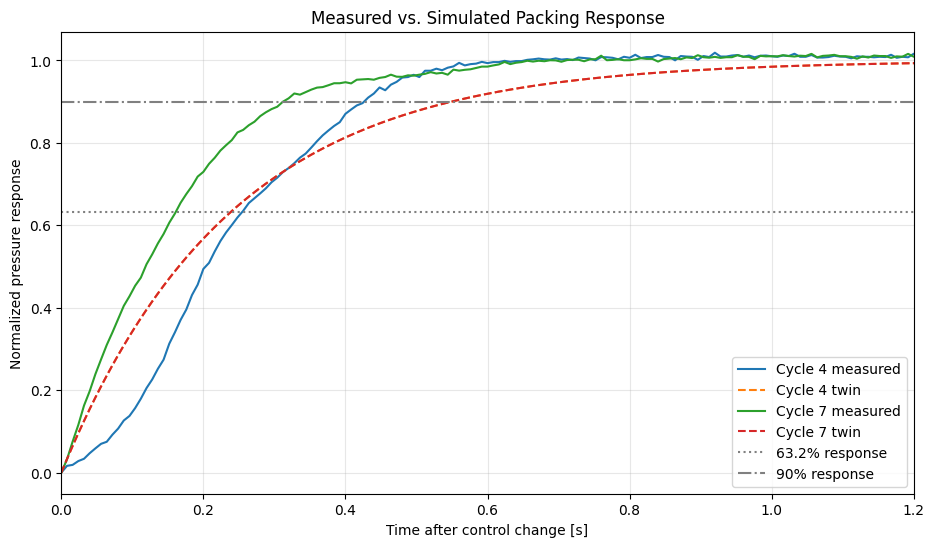

In [75]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rows = []

fig, ax = plt.subplots(figsize=(11, 6))

for n, data in {**cycles, **cycles_300}.items():
    t = data["time"].to_numpy()
    u = data["u_S"].to_numpy()
    measured = data["p_C"].to_numpy()

    p_ref = 200 if n <= 6 else 300
    predicted = hybrid_twin(data, p_ref, tau_p)

    switch = np.flatnonzero((t > 1.0) & (u > -0.9))[0]
    t0 = t[switch]

    r_measured = (
        (measured[switch:] - measured[switch]) /
        (p_ref - measured[switch])
    )

    r_model = (
        (predicted[switch:] - predicted[switch]) /
        (p_ref - predicted[switch])
    )

    def crossing_time(r, level):
        indices = np.flatnonzero(r >= level)
        if len(indices) == 0:
            return np.nan
        return t[switch + indices[0]] - t0

    tau_measured = crossing_time(r_measured, 1 - np.exp(-1))
    tau_model = crossing_time(r_model, 1 - np.exp(-1))

    t90_measured = crossing_time(r_measured, 0.9)
    t90_model = crossing_time(r_model, 0.9)

    rows.append([
        n, p_ref, tau_measured, tau_model,
        t90_measured, t90_model
    ])

    if n in [4, 7]:
        ax.plot(t[switch:] - t0, r_measured,
                label=f"Cycle {n} measured")
        ax.plot(t[switch:] - t0, r_model, "--",
                label=f"Cycle {n} twin")

response = pd.DataFrame(rows, columns=[
    "Cycle", "Target [bar]",
    "Measured t63 [s]", "Twin t63 [s]",
    "Measured t90 [s]", "Twin t90 [s]"
])

print(response.round(4).to_string(index=False))

ax.axhline(1 - np.exp(-1), color="gray", linestyle=":",
           label="63.2% response")
ax.axhline(0.9, color="gray", linestyle="-.",
           label="90% response")

ax.set_xlim(0, 1.2)
ax.set_xlabel("Time after control change [s]")
ax.set_ylabel("Normalized pressure response")
ax.set_title("Measured vs. Simulated Packing Response")
ax.grid(alpha=0.3)
ax.legend()
plt.show()


In [76]:

def hybrid_second_order(data, p_ref, tau):
    t = data["time"].to_numpy()
    q = data["v_S"].to_numpy()
    u = data["u_S"].to_numpy()

    F = cumulative_trapezoid(q, t, initial=0)
    p_hat = filling_model(F, theta_fill)

    switch = np.flatnonzero((t > 1.0) & (u > -0.9))[0]

    p_switch = p_hat[switch]
    dt = t[switch:] - t[switch]

    z = dt / tau

    p_hat[switch:] = p_ref + (p_switch - p_ref) * (
        1 + z
    ) * np.exp(-z)

    return p_hat


In [77]:

from scipy.optimize import least_squares

def fit_packing_tau(data, p_ref):
    t = data["time"].to_numpy()
    u = data["u_S"].to_numpy()
    p = data["p_C"].to_numpy()

    switch = np.flatnonzero((t > 1.0) & (u > -0.9))[0]

    def residual(x):
        prediction = hybrid_second_order(data, p_ref, x[0])
        return prediction[switch:] - p[switch:]

    result = least_squares(
        residual,
        x0=[0.1],
        bounds=([0.005], [1.0])
    )

    return result.x[0]

tau_200 = fit_packing_tau(cycles[4], 200)
tau_300 = fit_packing_tau(cycles_300[7], 300)

print(f"200 bar: tau = {tau_200:.4f} s")
print(f"300 bar: tau = {tau_300:.4f} s")


200 bar: tau = 0.1174 s
300 bar: tau = 0.0635 s


 Cycle  First-order RMSE  Second-order RMSE
     4             4.010              1.455
     5             5.592              3.589
     6             4.033              1.497
     7            11.069              5.069
     8            12.964              5.935
     9            15.506              8.177


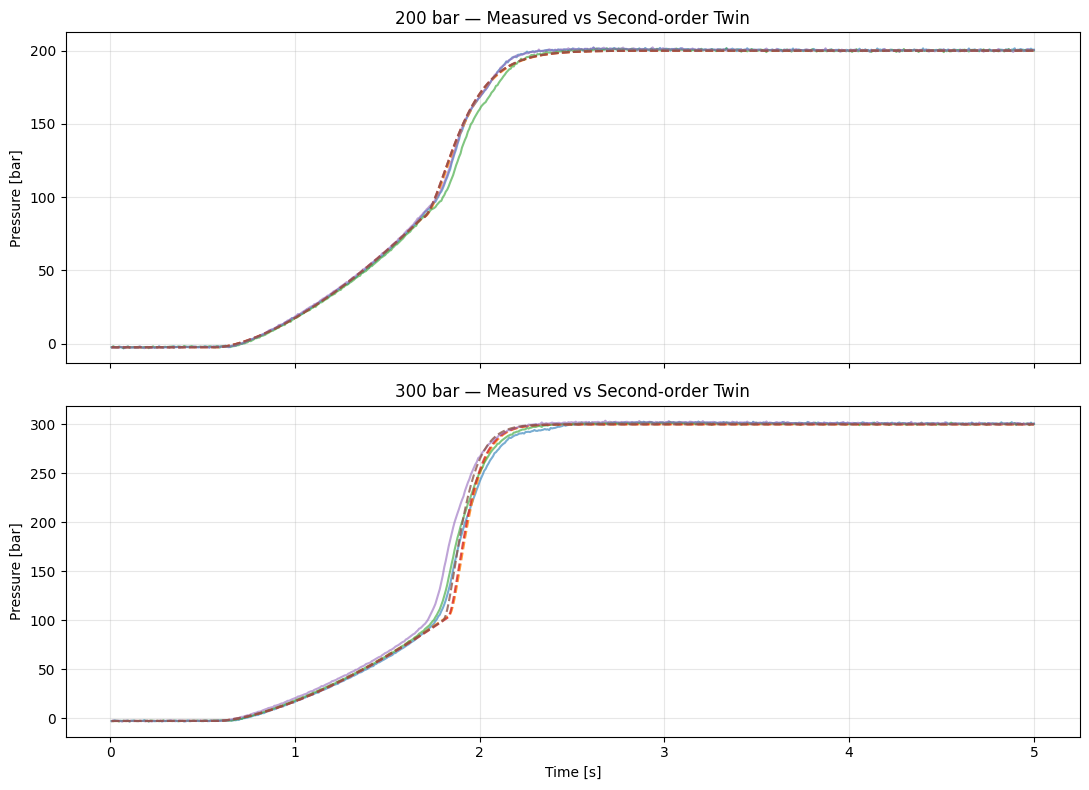

In [78]:

import pandas as pd
import matplotlib.pyplot as plt

rows = []

fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

for n, data in {**cycles, **cycles_300}.items():
    p_ref = 200 if n <= 6 else 300
    tau = tau_200 if n <= 6 else tau_300

    measured = data["p_C"].to_numpy()
    first = hybrid_twin(data, p_ref, tau_p)
    second = hybrid_second_order(data, p_ref, tau)

    rmse_first = np.sqrt(np.mean((measured - first)**2))
    rmse_second = np.sqrt(np.mean((measured - second)**2))

    rows.append([n, rmse_first, rmse_second])

    a = ax[0] if n <= 6 else ax[1]

    a.plot(data["time"], measured, alpha=0.6)
    a.plot(data["time"], second, "--", alpha=0.8)

results = pd.DataFrame(
    rows,
    columns=["Cycle", "First-order RMSE", "Second-order RMSE"]
)

print(results.round(3).to_string(index=False))

ax[0].set_title("200 bar — Measured vs Second-order Twin")
ax[1].set_title("300 bar — Measured vs Second-order Twin")

for a in ax:
    a.set_ylabel("Pressure [bar]")
    a.grid(alpha=0.3)

ax[-1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()


In [79]:

from scipy.optimize import least_squares
import numpy as np

def fit_first_order(data, target):
    t = data["time"].to_numpy()
    u = data["u_S"].to_numpy()
    measured = data["p_C"].to_numpy()

    switch = np.flatnonzero((t > 1.0) & (u > -0.9))[0]

    def residual(x):
        predicted = hybrid_twin(data, target, x[0])
        return predicted[switch:] - measured[switch:]

    fit = least_squares(
        residual,
        x0=[0.2],
        bounds=([0.005], [1.0])
    )
    return fit.x[0]

tau_first_200 = fit_first_order(cycles[4], 200)
tau_first_300 = fit_first_order(cycles_300[7], 300)

print(f"First-order, 200 bar: {tau_first_200:.4f} s")
print(f"First-order, 300 bar: {tau_first_300:.4f} s")


First-order, 200 bar: 0.2384 s
First-order, 300 bar: 0.1326 s


In [80]:

import pandas as pd

def rmse(actual, predicted):
    return np.sqrt(np.mean((actual - predicted)**2))

rows = []

for target, group, reference in [
    (200, cycles, 4),
    (300, cycles_300, 7)
]:
    for n, data in group.items():
        if n == reference:
            continue

        t = data["time"].to_numpy()
        measured = data["p_C"].to_numpy()

        replay = np.interp(
            t,
            group[reference]["time"],
            group[reference]["p_C"]
        )

        tau_first = tau_first_200 if target == 200 else tau_first_300
        tau_second = tau_200 if target == 200 else tau_300

        first = hybrid_twin(data, target, tau_first)
        second = hybrid_second_order(data, target, tau_second)

        rows.append([
            n, target,
            rmse(measured, replay),
            rmse(measured, first),
            rmse(measured, second)
        ])

comparison = pd.DataFrame(rows, columns=[
    "Cycle", "Target",
    "Replay RMSE", "First-order RMSE", "Second-order RMSE"
])

print(comparison.round(3).to_string(index=False))


 Cycle  Target  Replay RMSE  First-order RMSE  Second-order RMSE
     5     200        2.775             5.592              3.589
     6     200        0.659             4.033              1.497
     8     300        2.932             3.796              5.935
     9     300        8.677             6.355              8.177


In [81]:
def hybrid_c1(data, p_ref, tau):
    t = data["time"].to_numpy()
    q = data["v_S"].to_numpy()
    u = data["u_S"].to_numpy()

    F = cumulative_trapezoid(q, t, initial=0)
    p_hat = filling_model(F, theta_fill)

    switch = np.flatnonzero((t > 1.0) & (u > -0.9))[0]

    a, F0, b = theta_fill

    p_s = p_hat[switch]

    if F[switch] > F0:
        dp_s = a * b * (F[switch] - F0)**(b - 1) * q[switch]
    else:
        dp_s = 0.0

    dt = t[switch:] - t[switch]

    A = p_s - p_ref
    B = dp_s + A / tau

    p_hat[switch:] = p_ref + (A + B * dt) * np.exp(-dt / tau)

    return p_hat


In [82]:

from scipy.optimize import least_squares

def fit_c1_tau(data, p_ref):
    t = data["time"].to_numpy()
    u = data["u_S"].to_numpy()
    measured = data["p_C"].to_numpy()

    switch = np.flatnonzero((t > 1.0) & (u > -0.9))[0]

    def residual(x):
        predicted = hybrid_c1(data, p_ref, x[0])
        return predicted[switch:] - measured[switch:]

    result = least_squares(
        residual,
        x0=[0.1],
        bounds=([0.005], [1.0])
    )

    return result.x[0]

tau_c1_200 = fit_c1_tau(cycles[4], 200)
tau_c1_300 = fit_c1_tau(cycles_300[7], 300)

print(f"C1 model — 200 bar: tau = {tau_c1_200:.4f} s")
print(f"C1 model — 300 bar: tau = {tau_c1_300:.4f} s")


C1 model — 200 bar: tau = 0.1247 s
C1 model — 300 bar: tau = 0.0653 s


In [83]:

rows = []

for target, group, reference in [
    (200, cycles, 4),
    (300, cycles_300, 7)
]:
    for n, data in group.items():
        if n == reference:
            continue

        t = data["time"].to_numpy()
        measured = data["p_C"].to_numpy()

        replay = np.interp(
            t,
            group[reference]["time"],
            group[reference]["p_C"]
        )

        tau_first = tau_first_200 if target == 200 else tau_first_300
        tau_second = tau_200 if target == 200 else tau_300
        tau_c1 = tau_c1_200 if target == 200 else tau_c1_300

        first = hybrid_twin(data, target, tau_first)
        second = hybrid_second_order(data, target, tau_second)
        c1 = hybrid_c1(data, target, tau_c1)

        rows.append([
            n,
            rmse(measured, replay),
            rmse(measured, first),
            rmse(measured, second),
            rmse(measured, c1)
        ])

comparison_c1 = pd.DataFrame(rows, columns=[
    "Cycle", "Replay", "First-order",
    "Second-order", "C1 Hybrid"
])

print(comparison_c1.round(3).to_string(index=False))


 Cycle  Replay  First-order  Second-order  C1 Hybrid
     5   2.775        5.592         3.589      3.876
     6   0.659        4.033         1.497      1.845
     8   2.932        3.796         5.935      5.772
     9   8.677        6.355         8.177      8.067


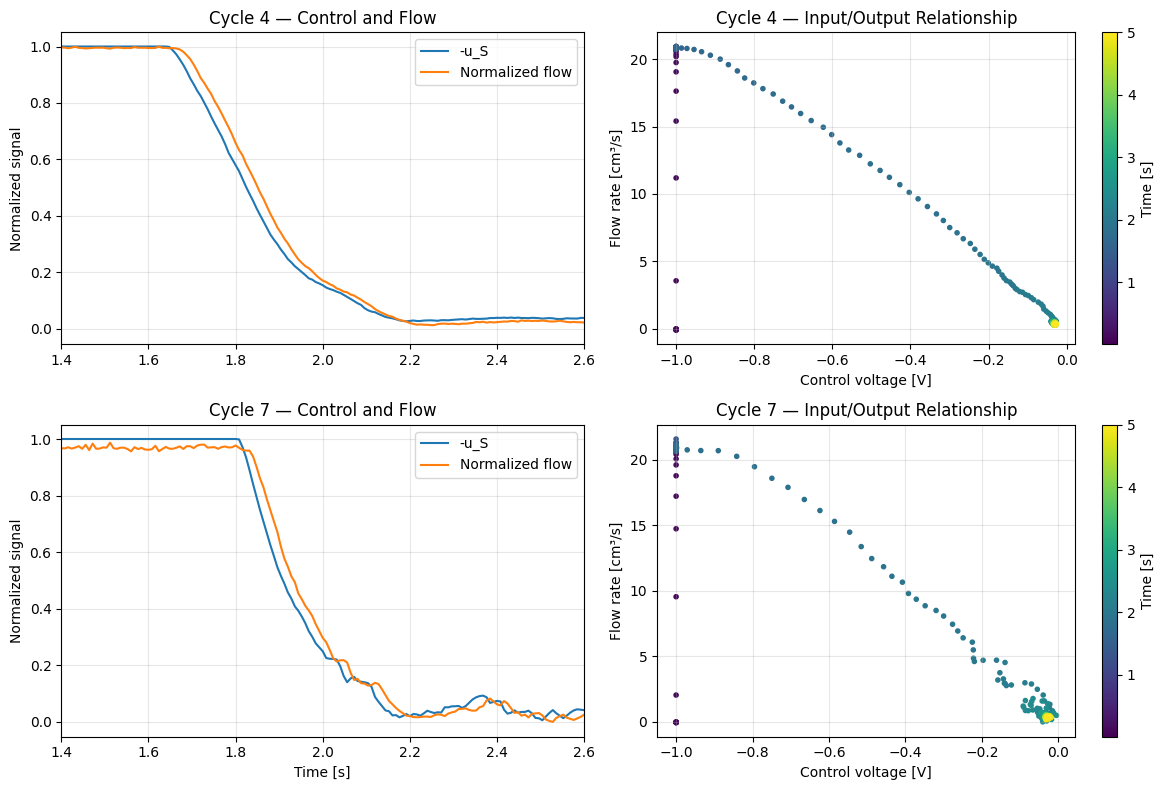

In [84]:

import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 2, figsize=(12, 8))

for row, (n, data) in enumerate([
    (4, cycles[4]),
    (7, cycles_300[7])
]):
    t = data["time"].to_numpy()
    u = data["u_S"].to_numpy()
    q = data["v_S"].to_numpy()

    # Şekilleri karşılaştırmak için iki sinyali normalize ediyoruz.
    ax[row, 0].plot(t, -u, label="-u_S")
    ax[row, 0].plot(t, q / np.max(q), label="Normalized flow")

    ax[row, 0].set_xlim(1.4, 2.6)
    ax[row, 0].set_ylabel("Normalized signal")
    ax[row, 0].set_title(f"Cycle {n} — Control and Flow")
    ax[row, 0].legend()
    ax[row, 0].grid(alpha=0.3)

    sc = ax[row, 1].scatter(
        u, q, c=t, cmap="viridis", s=9
    )

    ax[row, 1].set_xlabel("Control voltage [V]")
    ax[row, 1].set_ylabel("Flow rate [cm³/s]")
    ax[row, 1].set_title(f"Cycle {n} — Input/Output Relationship")
    ax[row, 1].grid(alpha=0.3)

    plt.colorbar(sc, ax=ax[row, 1], label="Time [s]")

ax[1, 0].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()


In [85]:

for n, data in [(4, cycles[4]), (7, cycles_300[7])]:
    idle = data[(data["time"] < 0.08)]
    filling = data[
        (data["time"] > 0.3) &
        (data["time"] < 1.5)
    ]

    print(f"\nCycle {n}")

    for name, part in [("Startup", idle), ("Filling", filling)]:
        print(
            f"{name}: "
            f"u = {part['u_S'].mean():.3f} V, "
            f"flow = {part['v_S'].mean():.3f} cm³/s"
        )



Cycle 4
Startup: u = -1.000 V, flow = -0.060 cm³/s
Filling: u = -1.000 V, flow = 20.831 cm³/s

Cycle 7
Startup: u = -1.000 V, flow = -0.049 cm³/s
Filling: u = -1.000 V, flow = 20.859 cm³/s


In [86]:

train = cycles[4]

q_max = train.loc[
    (train["time"] > 0.3) & (train["time"] < 1.5),
    "v_S"
].mean()

q_min = train.loc[
    (train["time"] > 3.0) & (train["time"] < 5.0),
    "v_S"
].mean()

print(f"Filling flow: {q_max:.3f} cm³/s")
print(f"Holding flow: {q_min:.3f} cm³/s")

def equilibrium_flow(u):
    command = np.clip(-u, 0, 1)
    return q_min + (q_max - q_min) * command


Filling flow: 20.831 cm³/s
Holding flow: 0.386 cm³/s


In [87]:

import numpy as np

def simulate_flow(data, tau):
    t = data["time"].to_numpy()
    u = data["u_S"].to_numpy()
    q = data["v_S"].to_numpy()

    switch = np.flatnonzero((t > 1.0) & (u > -0.9))[0]

    predicted = np.empty(len(t) - switch)
    predicted[0] = q[switch]

    for k in range(len(predicted) - 1):
        i = switch + k

        dt = t[i + 1] - t[i]
        alpha = np.exp(-dt / tau)

        predicted[k + 1] = (
            alpha * predicted[k]
            + (1 - alpha) * equilibrium_flow(u[i])
        )

    return t[switch:], q[switch:], predicted


In [88]:

from scipy.optimize import least_squares

def actuator_residual(x):
    t, measured, predicted = simulate_flow(cycles[4], x[0])

    mask = t <= 2.6

    return predicted[mask] - measured[mask]

fit = least_squares(
    actuator_residual,
    x0=[0.05],
    bounds=([0.001], [0.5])
)

tau_v = fit.x[0]

print(f"Actuator time constant: {tau_v:.4f} s")
print("Optimization succeeded:", fit.success)


Actuator time constant: 0.0175 s
Optimization succeeded: True


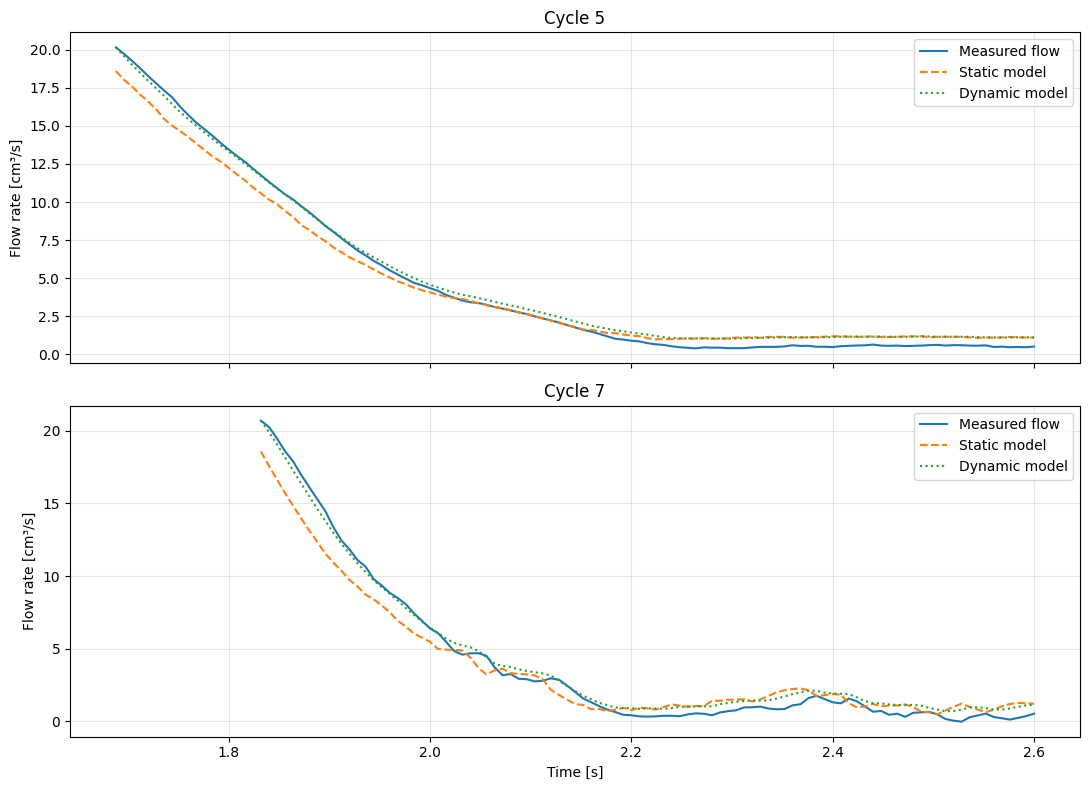

 Cycle  Static RMSE  Dynamic RMSE
     5       0.8093        0.4473
     6       0.8756        0.4748
     7       1.2094        0.4981
     8       1.2055        0.5116
     9       1.2702        0.5380


In [89]:

import pandas as pd
import matplotlib.pyplot as plt

rows = []

fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

for n, data in {**cycles, **cycles_300}.items():

    if n == 4:
        continue

    t, measured, dynamic = simulate_flow(data, tau_v)

    switch = np.flatnonzero(
        (data["time"].to_numpy() > 1.0) &
        (data["u_S"].to_numpy() > -0.9)
    )[0]

    static = equilibrium_flow(
        data["u_S"].to_numpy()[switch:]
    )

    mask = t <= 2.6

    rmse_static = np.sqrt(
        np.mean((measured[mask] - static[mask])**2)
    )

    rmse_dynamic = np.sqrt(
        np.mean((measured[mask] - dynamic[mask])**2)
    )

    rows.append([n, rmse_static, rmse_dynamic])

    if n in [5, 7]:
        a = ax[0] if n == 5 else ax[1]

        a.plot(t[mask], measured[mask], label="Measured flow")
        a.plot(t[mask], static[mask], "--", label="Static model")
        a.plot(t[mask], dynamic[mask], ":", label="Dynamic model")

        a.set_title(f"Cycle {n}")
        a.set_ylabel("Flow rate [cm³/s]")
        a.grid(alpha=0.3)
        a.legend()

ax[-1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()

flow_results = pd.DataFrame(
    rows,
    columns=["Cycle", "Static RMSE", "Dynamic RMSE"]
)

print(flow_results.round(4).to_string(index=False))


In [90]:

def flow_without_measured_initial(data, tau):
    t = data["time"].to_numpy()
    u = data["u_S"].to_numpy()

    switch = np.flatnonzero((t > 1.0) & (u > -0.9))[0]

    predicted = np.empty(len(t) - switch)
    predicted[0] = q_max

    for k in range(len(predicted) - 1):
        i = switch + k
        dt = t[i + 1] - t[i]
        alpha = np.exp(-dt / tau)

        predicted[k + 1] = (
            alpha * predicted[k]
            + (1 - alpha) * equilibrium_flow(u[i])
        )

    return t[switch:], predicted


reference = cycles[4]

t_ref = reference["time"].to_numpy()
u_ref = reference["u_S"].to_numpy()
q_ref = reference["v_S"].to_numpy()

i_ref = np.flatnonzero((t_ref > 1.0) & (u_ref > -0.9))[0]
switch_time_ref = t_ref[i_ref]

rows = []

for n, data in {**cycles, **cycles_300}.items():
    if n == 4:
        continue

    t, dynamic = flow_without_measured_initial(data, tau_v)

    u = data["u_S"].to_numpy()
    q = data["v_S"].to_numpy()

    switch = np.flatnonzero(
        (data["time"].to_numpy() > 1.0) & (u > -0.9)
    )[0]

    measured = q[switch:]
    static = equilibrium_flow(u[switch:])

    # Cycle 4'ün geçiş eğrisini yeni çevrime hizala.
    aligned_time = t - t[0] + switch_time_ref
    replay = np.interp(aligned_time, t_ref, q_ref)

    mask = t <= 2.6

    rows.append([
        n,
        rmse(measured[mask], static[mask]),
        rmse(measured[mask], dynamic[mask]),
        rmse(measured[mask], replay[mask])
    ])

flow_comparison = pd.DataFrame(rows, columns=[
    "Cycle", "Static", "Dynamic", "Aligned Replay"
])

print(flow_comparison.round(3).to_string(index=False))


 Cycle  Static  Dynamic  Aligned Replay
     5   0.809    0.449           0.613
     6   0.876    0.480           0.122
     7   1.209    0.496           1.719
     8   1.205    0.510           1.861
     9   1.270    0.536           2.210


In [91]:

from scipy.optimize import minimize_scalar
import numpy as np

def simulate_delayed_flow(data, delay):
    t = data["time"].to_numpy()
    u = data["u_S"].to_numpy()

    switch = np.flatnonzero((t > 1.0) & (u > -0.9))[0]

    delayed_u = np.interp(t[switch:] - delay, t, u)
    predicted = equilibrium_flow(delayed_u)

    return t[switch:], predicted


def delay_error(delay):
    t, predicted = simulate_delayed_flow(cycles[4], delay)

    measured = cycles[4]["v_S"].to_numpy()
    u = cycles[4]["u_S"].to_numpy()
    time = cycles[4]["time"].to_numpy()

    switch = np.flatnonzero((time > 1.0) & (u > -0.9))[0]
    mask = t <= 2.6

    return np.mean((measured[switch:][mask] - predicted[mask])**2)


fit_delay = minimize_scalar(
    delay_error,
    bounds=(0, 0.1),
    method="bounded"
)

delay = fit_delay.x

print(f"Estimated delay: {delay * 1000:.2f} ms")


Estimated delay: 22.75 ms


In [92]:

rows = []

for n, data in {**cycles, **cycles_300}.items():
    if n == 4:
        continue

    t, delayed = simulate_delayed_flow(data, delay)
    _, dynamic = flow_without_measured_initial(data, tau_v)

    time = data["time"].to_numpy()
    u = data["u_S"].to_numpy()
    q = data["v_S"].to_numpy()

    switch = np.flatnonzero((time > 1.0) & (u > -0.9))[0]

    measured = q[switch:]
    mask = t <= 2.6

    rows.append([
        n,
        rmse(measured[mask], delayed[mask]),
        rmse(measured[mask], dynamic[mask])
    ])

delay_comparison = pd.DataFrame(
    rows,
    columns=["Cycle", "Pure Delay RMSE", "First-order RMSE"]
)

print(delay_comparison.round(3).to_string(index=False))


 Cycle  Pure Delay RMSE  First-order RMSE
     5            0.445             0.449
     6            0.466             0.480
     7            0.472             0.496
     8            0.493             0.510
     9            0.518             0.536


In [93]:

from scipy.optimize import least_squares
import numpy as np

def full_flow_model(data, t_on, tau_start):
    t = data["time"].to_numpy()
    u = data["u_S"].to_numpy()

    delayed_u = np.interp(t - delay, t, u)
    q_target = equilibrium_flow(delayed_u)

    elapsed = np.maximum(t - t_on, 0)
    startup = 1 - np.exp(-elapsed / tau_start)

    return startup * q_target


train = cycles[4]
t_train = train["time"].to_numpy()
q_train = train["v_S"].to_numpy()

mask = t_train <= 0.4

fit_start = least_squares(
    lambda x: (
        full_flow_model(train, x[0], x[1])[mask]
        - q_train[mask]
    ),
    x0=[0.09, 0.02],
    bounds=([0, 0.001], [0.2, 0.2])
)

t_on, tau_start = fit_start.x

print(f"Injection start: {t_on:.4f} s")
print(f"Startup time constant: {tau_start:.4f} s")


Injection start: 0.0933 s
Startup time constant: 0.0141 s


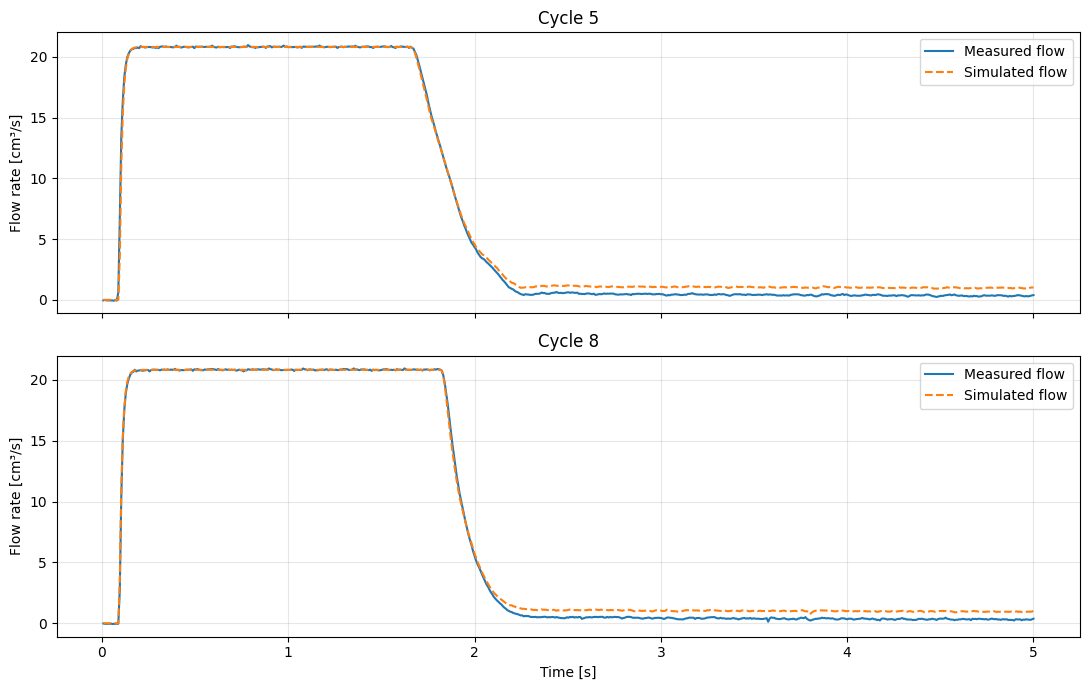

 Cycle  Full-cycle Flow RMSE
     4                 0.483
     5                 0.505
     6                 0.485
     7                 0.565
     8                 0.481
     9                 0.505


In [94]:

import pandas as pd
import matplotlib.pyplot as plt

rows = []

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

for n, data in {**cycles, **cycles_300}.items():
    t = data["time"].to_numpy()
    measured = data["v_S"].to_numpy()

    predicted = full_flow_model(data, t_on, tau_start)

    error = rmse(measured, predicted)
    rows.append([n, error])

    if n in [5, 8]:
        a = ax[0] if n == 5 else ax[1]

        a.plot(t, measured, label="Measured flow")
        a.plot(t, predicted, "--", label="Simulated flow")

        a.set_title(f"Cycle {n}")
        a.set_ylabel("Flow rate [cm³/s]")
        a.legend()
        a.grid(alpha=0.3)

ax[-1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()

flow_full_results = pd.DataFrame(
    rows, columns=["Cycle", "Full-cycle Flow RMSE"]
)

print(flow_full_results.round(3).to_string(index=False))


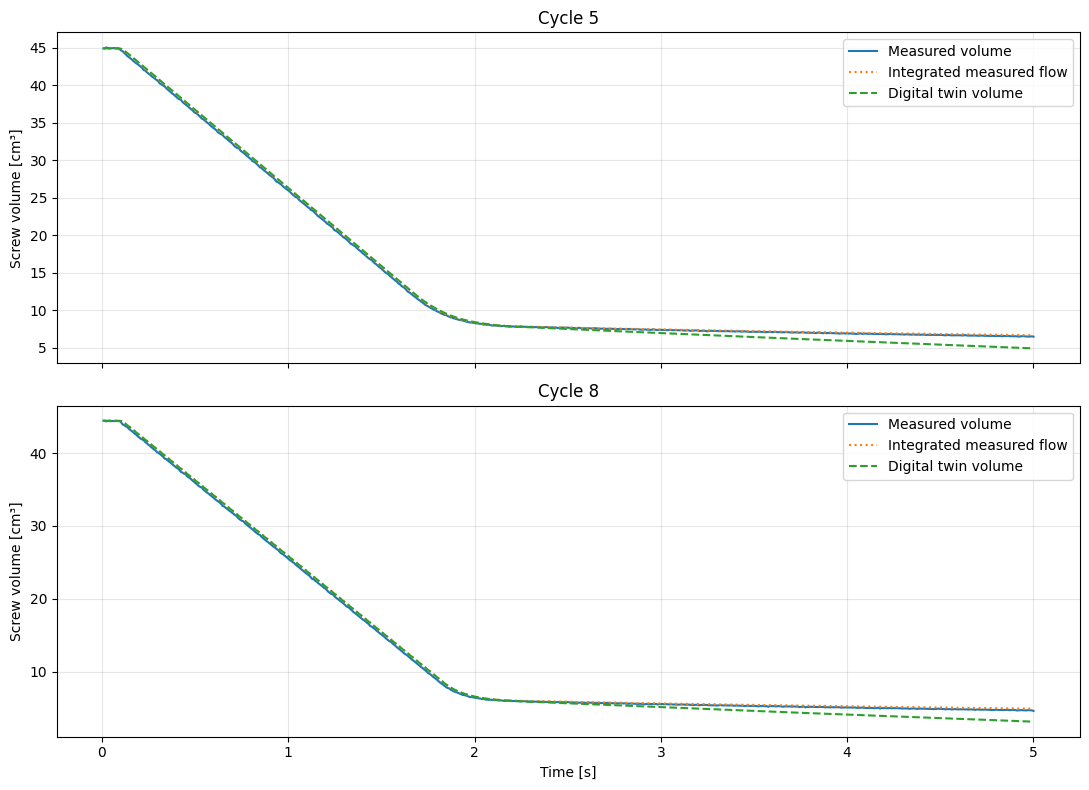

 Cycle  Volume RMSE [cm³]  Final volume error [cm³]
     4              0.757                    -1.685
     5              0.710                    -1.562
     6              0.726                    -1.600
     7              0.647                    -1.399
     8              0.690                    -1.476
     9              0.636                    -1.417


In [95]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid

rows = []

fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

for n, data in {**cycles, **cycles_300}.items():
    t = data["time"].to_numpy()

    q_measured = data["v_S"].to_numpy()
    V_measured = data["V_S"].to_numpy()

    q_predicted = full_flow_model(data, t_on, tau_start)

    V_from_measured_flow = V_measured[0] - cumulative_trapezoid(
        q_measured, t, initial=0
    )

    V_predicted = V_measured[0] - cumulative_trapezoid(
        q_predicted, t, initial=0
    )

    volume_rmse = np.sqrt(np.mean(
        (V_measured - V_predicted)**2
    ))

    final_error = V_predicted[-1] - V_measured[-1]

    rows.append([n, volume_rmse, final_error])

    if n in [5, 8]:
        a = ax[0] if n == 5 else ax[1]

        a.plot(t, V_measured, label="Measured volume")
        a.plot(t, V_from_measured_flow, ":",
               label="Integrated measured flow")
        a.plot(t, V_predicted, "--",
               label="Digital twin volume")

        a.set_title(f"Cycle {n}")
        a.set_ylabel("Screw volume [cm³]")
        a.grid(alpha=0.3)
        a.legend()

ax[-1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()

volume_results = pd.DataFrame(
    rows, columns=[
        "Cycle", "Volume RMSE [cm³]",
        "Final volume error [cm³]"
    ]
)

print(volume_results.round(3).to_string(index=False))


In [96]:

import numpy as np
import pandas as pd
from scipy.integrate import trapezoid

rows = []

for n, data in {**cycles, **cycles_300}.items():
    t = data["time"].to_numpy()
    u = data["u_S"].to_numpy()
    q = data["v_S"].to_numpy()

    q_hat = full_flow_model(data, t_on, tau_start)

    for phase, start, end in [
        ("Filling", 0.0, 1.5),
        ("Transition", 1.5, 2.3),
        ("Holding", 2.3, 5.0)
    ]:
        mask = (t >= start) & (t <= end)

        volume_bias = trapezoid(
            q_hat[mask] - q[mask],
            t[mask]
        )

        rows.append([
            n,
            phase,
            q[mask].mean(),
            q_hat[mask].mean(),
            u[mask].mean(),
            volume_bias
        ])

diagnostics = pd.DataFrame(rows, columns=[
    "Cycle", "Phase", "Measured flow",
    "Model flow", "Mean voltage",
    "Integrated flow error [cm³]"
])

print(diagnostics.round(3).to_string(index=False))


 Cycle      Phase  Measured flow  Model flow  Mean voltage  Integrated flow error [cm³]
     4    Filling         19.385      19.393        -1.000                        0.012
     4 Transition          9.788       9.960        -0.441                        0.135
     4    Holding          0.415       1.045        -0.032                        1.699
     5    Filling         19.434      19.393        -1.000                       -0.062
     5 Transition         10.046      10.197        -0.452                        0.119
     5    Holding          0.417       1.041        -0.032                        1.684
     6    Filling         19.403      19.393        -1.000                       -0.015
     6 Transition          9.668       9.834        -0.435                        0.130
     6    Holding          0.407       1.036        -0.032                        1.696
     7    Filling         19.497      19.393        -1.000                       -0.155
     7 Transition         12.210

In [97]:

hold = cycles[4].loc[
    (cycles[4]["time"] >= 2.3) &
    (cycles[4]["time"] <= 5.0)
]

u_hold = hold["u_S"].mean()
q_hold = hold["v_S"].mean()

print(f"Holding voltage: {u_hold:.5f} V")
print(f"Holding flow: {q_hold:.5f} cm³/s")


Holding voltage: -0.03221 V
Holding flow: 0.41509 cm³/s


In [98]:

def equilibrium_flow_corrected(u):
    fraction = (u_hold - u) / (u_hold + 1.0)
    fraction = np.clip(fraction, 0, 1)

    return q_hold + (q_max - q_hold) * fraction


def full_flow_corrected(data):
    t = data["time"].to_numpy()
    u = data["u_S"].to_numpy()

    delayed_u = np.interp(t - delay, t, u)
    q_target = equilibrium_flow_corrected(delayed_u)

    elapsed = np.maximum(t - t_on, 0)
    startup = 1 - np.exp(-elapsed / tau_start)

    return startup * q_target


In [99]:

from scipy.integrate import cumulative_trapezoid
import numpy as np
import pandas as pd

rows = []

for n, data in {**cycles, **cycles_300}.items():
    t = data["time"].to_numpy()
    V = data["V_S"].to_numpy()

    q_old = full_flow_model(data, t_on, tau_start)
    q_new = full_flow_corrected(data)

    V_old = V[0] - cumulative_trapezoid(q_old, t, initial=0)
    V_new = V[0] - cumulative_trapezoid(q_new, t, initial=0)

    rows.append([
        n,
        rmse(V, V_old),
        rmse(V, V_new),
        V_old[-1] - V[-1],
        V_new[-1] - V[-1]
    ])

volume_comparison = pd.DataFrame(rows, columns=[
    "Cycle", "Old RMSE", "Corrected RMSE",
    "Old final error", "Corrected final error"
])

print(volume_comparison.round(3).to_string(index=False))


 Cycle  Old RMSE  Corrected RMSE  Old final error  Corrected final error
     4     0.757           0.237           -1.685                  0.218
     5     0.710           0.316           -1.562                  0.338
     6     0.726           0.293           -1.600                  0.302
     7     0.647           0.384           -1.399                  0.370
     8     0.690           0.291           -1.476                  0.339
     9     0.636           0.392           -1.417                  0.409


In [100]:

import numpy as np
from scipy.integrate import cumulative_trapezoid

def control_to_filling_pressure(data):
    t = data["time"].to_numpy()
    u = data["u_S"].to_numpy()

    # Kontrol geriliminden debi tahmini
    q_hat = full_flow_corrected(data)

    # Tahmin edilen debiden hacim
    F_hat = cumulative_trapezoid(q_hat, t, initial=0)

    # Tahmin edilen hacimden basınç
    p_hat = filling_model(F_hat, theta_fill)

    # Kontrol çıkışındaki geçiş anı
    switch = np.flatnonzero((t > 1.0) & (u > -0.9))[0]

    return F_hat[:switch], p_hat[:switch]


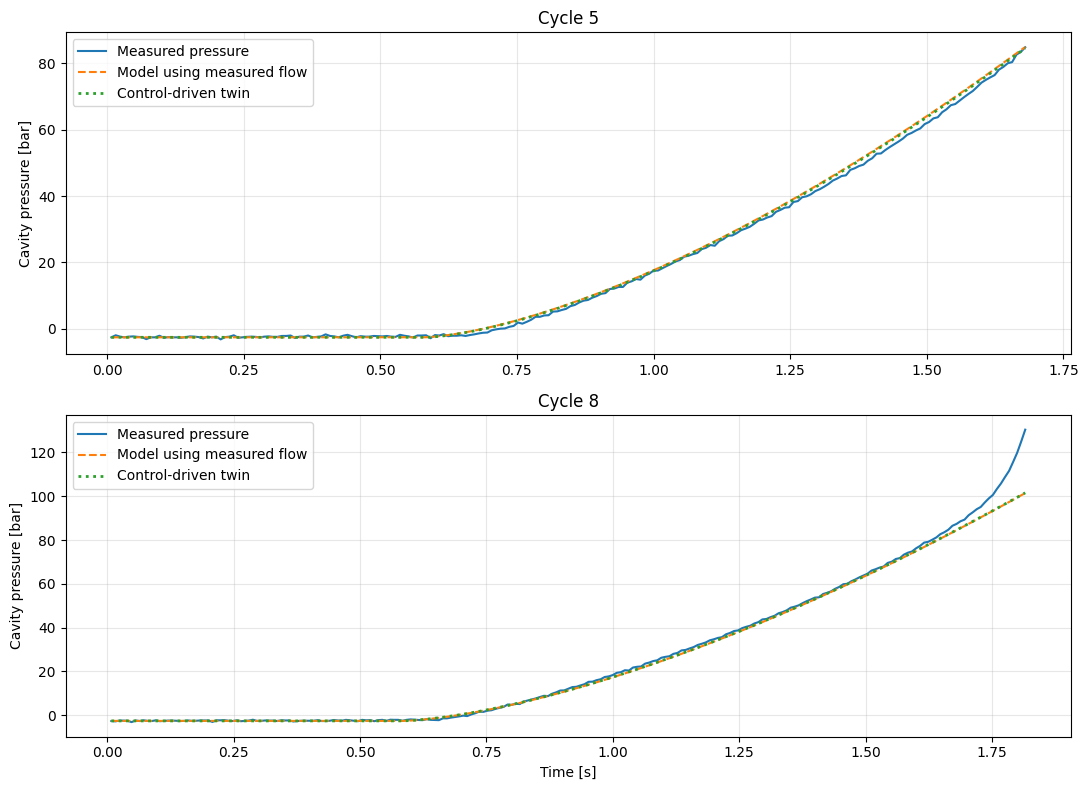

 Cycle  Measured-flow RMSE [bar]  Control-driven RMSE [bar]
     4                     0.479                      0.480
     5                     1.067                      0.890
     6                     0.672                      0.711
     7                     2.746                      2.806
     8                     3.677                      3.643
     9                     5.910                      6.089


In [101]:

import pandas as pd
import matplotlib.pyplot as plt

rows = []

fig, ax = plt.subplots(2, 1, figsize=(11, 8))

for n, data in {**cycles, **cycles_300}.items():
    t = data["time"].to_numpy()
    q = data["v_S"].to_numpy()

    u = data["u_S"].to_numpy()
    switch = np.flatnonzero((t > 1.0) & (u > -0.9))[0]

    measured = data["p_C"].to_numpy()[:switch]

    F_measured = cumulative_trapezoid(q, t, initial=0)[:switch]
    p_from_measured_flow = filling_model(F_measured, theta_fill)

    F_twin, p_twin = control_to_filling_pressure(data)

    rmse_measured_flow = rmse(measured, p_from_measured_flow)
    rmse_control = rmse(measured, p_twin)

    rows.append([n, rmse_measured_flow, rmse_control])

    if n in [5, 8]:
        a = ax[0] if n == 5 else ax[1]

        a.plot(t[:switch], measured, label="Measured pressure")
        a.plot(t[:switch], p_from_measured_flow, "--",
               label="Model using measured flow")
        a.plot(t[:switch], p_twin, ":",
               label="Control-driven twin", linewidth=2)

        a.set_title(f"Cycle {n}")
        a.set_ylabel("Cavity pressure [bar]")
        a.grid(alpha=0.3)
        a.legend()

ax[-1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()

pressure_comparison = pd.DataFrame(
    rows,
    columns=[
        "Cycle",
        "Measured-flow RMSE [bar]",
        "Control-driven RMSE [bar]"
    ]
)

print(pressure_comparison.round(3).to_string(index=False))


In [102]:

def full_pressure_twin(data, p_ref, tau, order=1):
    t = data["time"].to_numpy()
    u = data["u_S"].to_numpy()

    # Gerilim -> debi -> hacim -> dolum basıncı
    q_hat = full_flow_corrected(data)
    F_hat = cumulative_trapezoid(q_hat, t, initial=0)
    p_hat = filling_model(F_hat, theta_fill)

    # Kontrol geçişi
    switch = np.flatnonzero((t > 1.0) & (u > -0.9))[0]

    p_switch = p_hat[switch]
    dt = t[switch:] - t[switch]

    if order == 1:
        p_hat[switch:] = p_ref + (
            p_switch - p_ref
        ) * np.exp(-dt / tau)

    elif order == 2:
        z = dt / tau
        p_hat[switch:] = p_ref + (
            p_switch - p_ref
        ) * (1 + z) * np.exp(-z)

    else:
        raise ValueError("order must be 1 or 2")

    return p_hat


In [103]:

rows = []

for target, group, reference in [
    (200, cycles, 4),
    (300, cycles_300, 7)
]:
    for n, data in group.items():
        if n == reference:
            continue

        t = data["time"].to_numpy()
        measured = data["p_C"].to_numpy()

        replay = np.interp(
            t,
            group[reference]["time"],
            group[reference]["p_C"]
        )

        tau1 = tau_first_200 if target == 200 else tau_first_300
        tau2 = tau_200 if target == 200 else tau_300

        first = full_pressure_twin(data, target, tau1, order=1)
        second = full_pressure_twin(data, target, tau2, order=2)

        rows.append([
            n,
            rmse(measured, replay),
            rmse(measured, first),
            rmse(measured, second)
        ])

full_results = pd.DataFrame(rows, columns=[
    "Cycle", "Replay RMSE",
    "Full Twin 1st RMSE", "Full Twin 2nd RMSE"
])

print(full_results.round(3).to_string(index=False))


 Cycle  Replay RMSE  Full Twin 1st RMSE  Full Twin 2nd RMSE
     5        2.775               5.537               3.528
     6        0.659               4.027               1.498
     8        2.932               3.776               5.917
     9        8.677               6.456               8.273


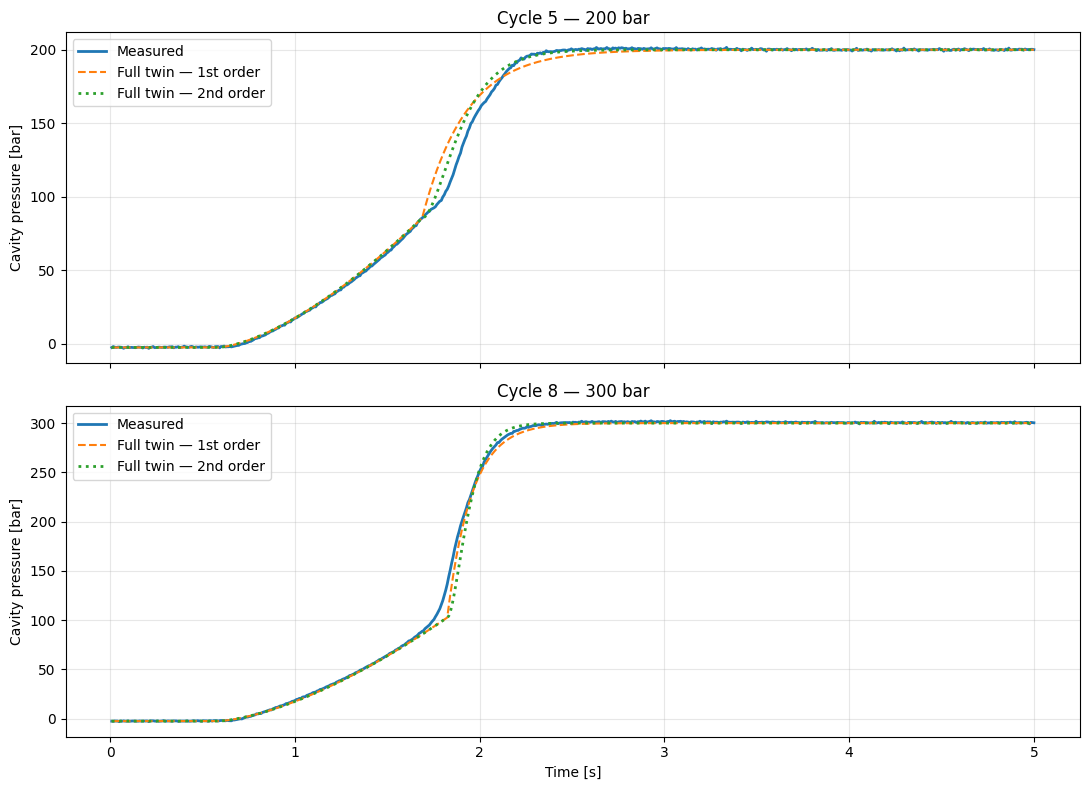

In [104]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

for a, n, data, target in [
    (ax[0], 5, cycles[5], 200),
    (ax[1], 8, cycles_300[8], 300)
]:
    tau1 = tau_first_200 if target == 200 else tau_first_300
    tau2 = tau_200 if target == 200 else tau_300

    first = full_pressure_twin(data, target, tau1, order=1)
    second = full_pressure_twin(data, target, tau2, order=2)

    a.plot(data["time"], data["p_C"],
           label="Measured", linewidth=2)
    a.plot(data["time"], first, "--",
           label="Full twin — 1st order")
    a.plot(data["time"], second, ":",
           label="Full twin — 2nd order", linewidth=2)

    a.set_title(f"Cycle {n} — {target} bar")
    a.set_ylabel("Cavity pressure [bar]")
    a.grid(alpha=0.3)
    a.legend()

ax[-1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()


In [105]:

import zipfile
import pandas as pd
from io import StringIO

disturbance = {}

with zipfile.ZipFile(filename) as z:
    for target, cycle in [(200, 1), (300, 18)]:

        path = (
            f"figures/figure8/"
            f"againstDisturbance-{target}bar-cycle{cycle}.txt"
        )

        text = z.read(path).decode("utf-8")
        data = pd.read_csv(StringIO(text), sep=r"\s+")

        disturbance[target] = data

        print(f"\n{target} bar — Cycle {cycle}")
        print("Columns:", data.columns.tolist())
        print("Shape:", data.shape)
        print(data.head(3).to_string(index=False))
        print()
        print(data.agg(["min", "max"]).round(3))



200 bar — Cycle 1
Columns: ['time', 'p_C', 'p_S', 'v_S', 'V_S', 'u_S']
Shape: (2855, 6)
 time       p_C       p_S       v_S       V_S  u_S
0.000 -2.211152 12.390137 -0.034976 44.856222  0.0
0.008 -2.349349 12.301636 -0.026902 44.838374 -1.0
0.016 -2.895557 11.841431 -0.065072 44.844131 -1.0

       time      p_C      p_S     v_S     V_S  u_S
min   0.000   -4.541   11.753 -13.791   5.927 -1.0
max  22.832  202.241  255.874  21.451  44.935  0.0

300 bar — Cycle 18
Columns: ['time', 'p_C', 'p_S', 'v_S', 'V_S', 'u_S']
Shape: (3064, 6)
 time       p_C      p_S       v_S       V_S  u_S
0.000 -2.691552 1.787720 -0.080486 44.633987  0.0
0.008 -2.415157 2.610779 -0.004147 44.712287 -1.0
0.016 -2.487546 1.876221 -0.072412 44.682349 -1.0

       time      p_C      p_S     v_S     V_S  u_S
min   0.000   -7.634    1.602 -12.094   3.669 -1.0
max  24.504  308.133  377.970  20.972  45.403  0.0


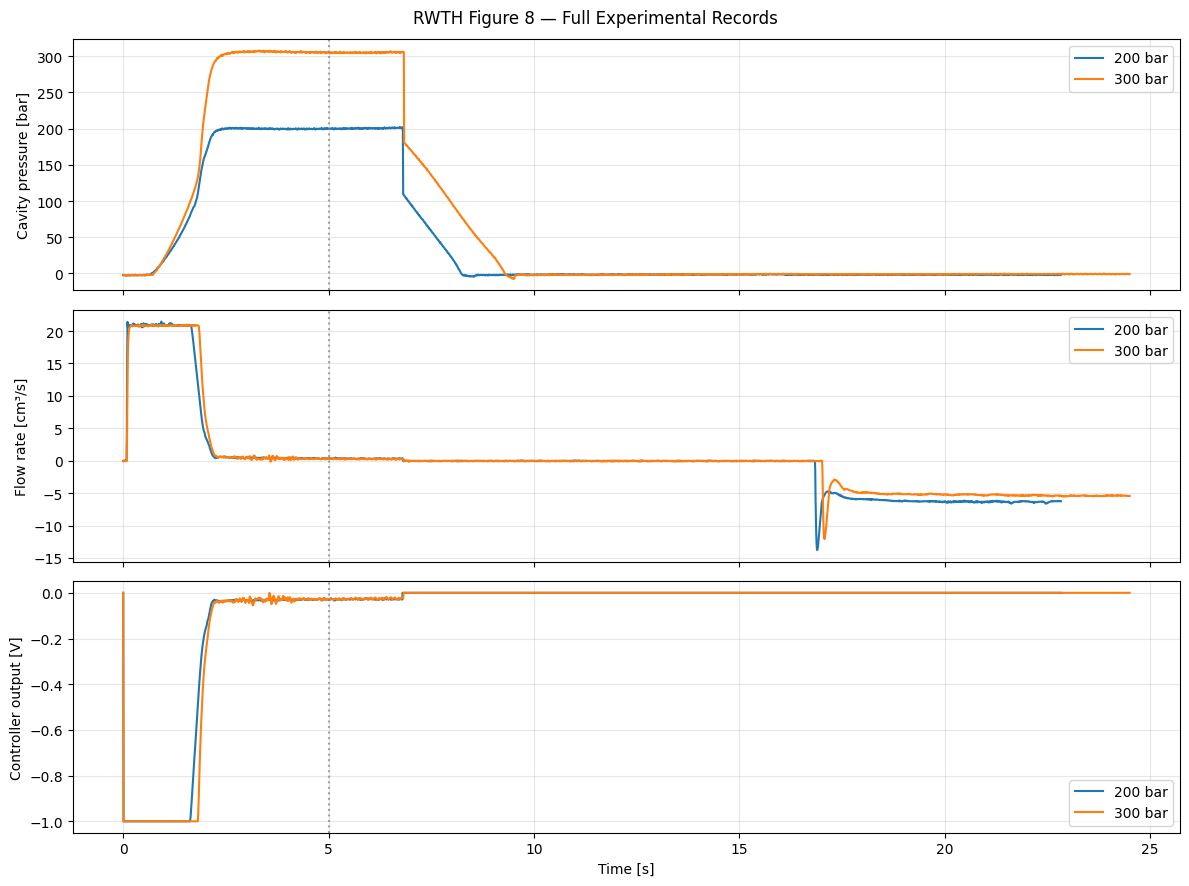

In [106]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for target, data in disturbance.items():
    t = data["time"]

    ax[0].plot(t, data["p_C"], label=f"{target} bar")
    ax[1].plot(t, data["v_S"], label=f"{target} bar")
    ax[2].plot(t, data["u_S"], label=f"{target} bar")

ax[0].set_ylabel("Cavity pressure [bar]")
ax[1].set_ylabel("Flow rate [cm³/s]")
ax[2].set_ylabel("Controller output [V]")
ax[2].set_xlabel("Time [s]")

for a in ax:
    a.axvline(5, color="gray", linestyle=":", alpha=0.7)
    a.grid(alpha=0.3)
    a.legend()

plt.suptitle("RWTH Figure 8 — Full Experimental Records")
plt.tight_layout()
plt.show()


In [107]:

import numpy as np
import pandas as pd
from scipy.integrate import cumulative_trapezoid

rows = []

for target, cycle, reference, tau, order in [
    (200, 1, cycles[4], tau_200, 2),
    (300, 18, cycles_300[7], tau_first_300, 1)
]:
    data = disturbance[target]
    test = data.loc[data["time"] <= 5.0].copy()

    t = test["time"].to_numpy()
    p_measured = test["p_C"].to_numpy()
    q_measured = test["v_S"].to_numpy()
    V_measured = test["V_S"].to_numpy()

    # Önceden kalibre edilmiş modeller — yeniden öğrenme yok.
    p_twin = full_pressure_twin(test, target, tau, order)
    q_twin = full_flow_corrected(test)
    V_twin = V_measured[0] - cumulative_trapezoid(
        q_twin, t, initial=0
    )

    # Başka deney ailesinden Cycle Replay baseline.
    p_replay = np.interp(
        t,
        reference["time"],
        reference["p_C"]
    )

    rows.append([
        target,
        cycle,
        rmse(p_measured, p_replay),
        rmse(p_measured, p_twin),
        rmse(q_measured, q_twin),
        rmse(V_measured, V_twin)
    ])

transfer_results = pd.DataFrame(rows, columns=[
    "Target", "Cycle", "Replay pressure RMSE",
    "Twin pressure RMSE", "Flow RMSE", "Volume RMSE"
])

print(transfer_results.round(3).to_string(index=False))


 Target  Cycle  Replay pressure RMSE  Twin pressure RMSE  Flow RMSE  Volume RMSE
    200      1                 1.329               2.671      0.706        0.564
    300     18                 7.609               8.606      0.187        0.314


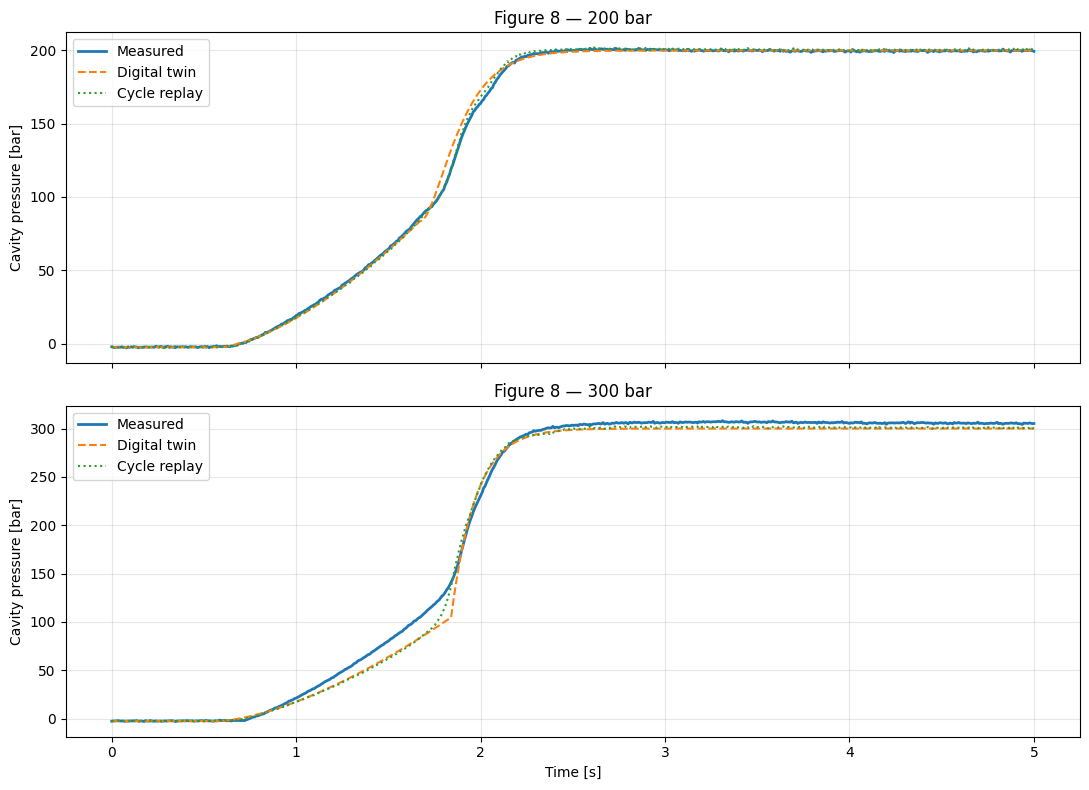

In [108]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

for a, target, reference, tau, order in [
    (ax[0], 200, cycles[4], tau_200, 2),
    (ax[1], 300, cycles_300[7], tau_first_300, 1)
]:
    test = disturbance[target].loc[
        disturbance[target]["time"] <= 5.0
    ]

    t = test["time"].to_numpy()

    twin = full_pressure_twin(test, target, tau, order)

    replay = np.interp(
        t, reference["time"], reference["p_C"]
    )

    a.plot(t, test["p_C"], label="Measured", linewidth=2)
    a.plot(t, twin, "--", label="Digital twin")
    a.plot(t, replay, ":", label="Cycle replay")

    a.set_title(f"Figure 8 — {target} bar")
    a.set_ylabel("Cavity pressure [bar]")
    a.grid(alpha=0.3)
    a.legend()

ax[-1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()


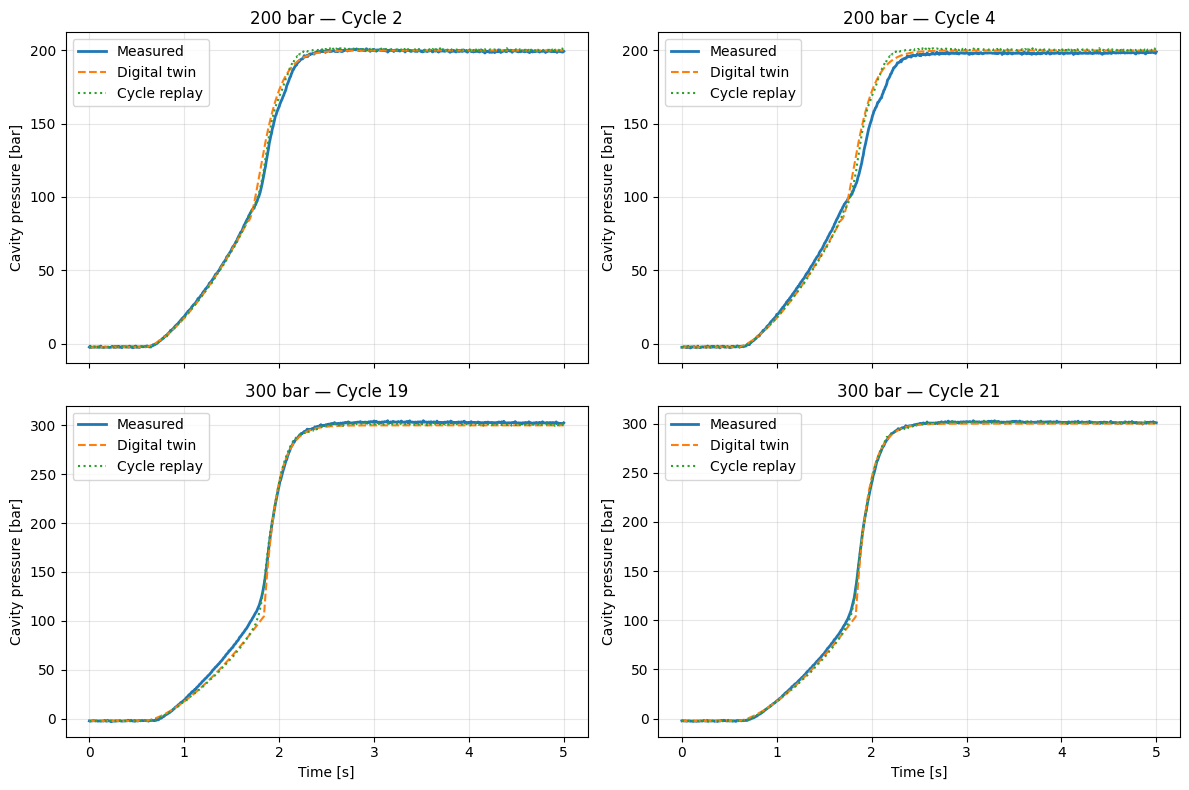

 Target  Cycle  Replay RMSE [bar]  Twin RMSE [bar]  Holding bias [bar]
    200      2              2.064            3.410              -0.279
    200      4              5.279            5.732              -1.797
    300     19              3.756            4.992               2.910
    300     21              1.726            3.266               1.362


In [109]:

import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO

tests = [(200, 2), (200, 4), (300, 19), (300, 21)]

rows = []
fig, ax = plt.subplots(2, 2, figsize=(12, 8), sharex=True)

with zipfile.ZipFile(filename) as z:
    for a, (target, n) in zip(ax.flat, tests):
        path = f"figures/figure8/againstDisturbance-{target}bar-cycle{n}.txt"

        data = pd.read_csv(
            StringIO(z.read(path).decode("utf-8")),
            sep=r"\s+"
        )

        data = data.loc[data["time"] <= 5.0].copy()

        t = data["time"].to_numpy()
        measured = data["p_C"].to_numpy()

        if target == 200:
            tau, order = tau_200, 2
            reference = cycles[4]
        else:
            tau, order = tau_first_300, 1
            reference = cycles_300[7]

        twin = full_pressure_twin(data, target, tau, order)

        replay = np.interp(
            t,
            reference["time"],
            reference["p_C"]
        )

        holding = (t >= 2.5) & (t <= 5.0)
        bias = np.mean(measured[holding] - twin[holding])

        rows.append([
            target, n,
            rmse(measured, replay),
            rmse(measured, twin),
            bias
        ])

        a.plot(t, measured, label="Measured", linewidth=2)
        a.plot(t, twin, "--", label="Digital twin")
        a.plot(t, replay, ":", label="Cycle replay")

        a.set_title(f"{target} bar — Cycle {n}")
        a.set_ylabel("Cavity pressure [bar]")
        a.grid(alpha=0.3)
        a.legend()

ax[1, 0].set_xlabel("Time [s]")
ax[1, 1].set_xlabel("Time [s]")

plt.tight_layout()
plt.show()

final_validation = pd.DataFrame(rows, columns=[
    "Target", "Cycle", "Replay RMSE [bar]",
    "Twin RMSE [bar]", "Holding bias [bar]"
])

print(final_validation.round(3).to_string(index=False))
